# Детекция и сегментация планктона на неразмеченных снимках

Ruslan Papina, группа М25-555

66 снимков из микроскопа без разметки. Детекция: YOLO11 и Faster R-CNN с весами COCO, сегментация по боксам Faster R-CNN: GrabCut и SAM 2. Результаты в `results/`.

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import cv2
import torch
import torchvision
import matplotlib.pyplot as plt
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from ultralytics import YOLO, SAM

DATA = "data/images"
OUT = "results"
DRIVE = "https://drive.google.com/drive/folders/1LT2NdDSULHiW3FwzT63ewgVO3pwRRhOW"
SEED = 42

%config InlineBackend.figure_formats = ["jpeg"]

torch.manual_seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 72
for d in ["analysis", "aug", "detection", "segmentation"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)
os.makedirs("weights", exist_ok=True)

In [2]:
if not os.path.isdir(DATA) or not os.listdir(DATA):
    import gdown
    gdown.download_folder(DRIVE, output=DATA, quiet=True)

files = sorted(f for f in os.listdir(DATA) if f.lower().endswith(".jpg"))
len(files)

66

In [3]:
def load(name):
    return cv2.imread(f"{DATA}/{name}")


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def save_fig(fig, path):
    fig.savefig(path, dpi=100, bbox_inches="tight")

## 1. Анализ данных и аугментации

### 1.1 Исходные снимки

Размер, яркость, контраст, фон, резкость. Объекты и перекрытия грубо оцениваю порогом (Отсу + морфология).

In [4]:
def blobs(img, min_area=500):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    k = 1024 / gray.shape[1]
    small = cv2.resize(gray, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (5, 5), 0)
    _, m = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    res = []
    for c in contours:
        a = cv2.contourArea(c)
        if a < min_area:
            continue
        hull = cv2.contourArea(cv2.convexHull(c))
        x, y, w, h = cv2.boundingRect(c)
        res.append({"area": a / k ** 2, "solidity": a / hull, "box": [x / k, y / k, (x + w) / k, (y + h) / k]})
    return res


def image_stats(name):
    img = load(name)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    p2, p50, p98 = np.percentile(gray, [2, 50, 98])
    b = blobs(img)
    areas = np.array([x["area"] for x in b]) if b else np.array([0.0])
    merged = sum(1 for x in b if x["area"] > 1.8 * np.median(areas) and x["solidity"] < 0.85)
    return {
        "image": name,
        "w": img.shape[1],
        "h": img.shape[0],
        "mean": gray.mean(),
        "rms_contrast": gray.std(),
        "michelson": (p98 - p2) / (p98 + p2),
        "background": p50,
        "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(),
        "n_blobs": len(b),
        "obj_diam_median": np.sqrt(np.median(areas) * 4 / np.pi),
        "obj_diam_max": np.sqrt(areas.max() * 4 / np.pi),
        "merged_blobs": merged,
    }


stats = pd.DataFrame([image_stats(f) for f in files])
stats.to_csv(f"{OUT}/analysis/image_stats.csv", index=False)
stats.describe().round(2)

,w,h,mean,rms_contrast,michelson,background,sharpness,n_blobs,obj_diam_median,obj_diam_max,merged_blobs
count,66.00,66.00,66.00,66.00,66.00,66.00,66.00,66.00,66.00,66.00,66.00
mean,2056.24,1542.18,179.97,24.51,0.36,188.17,5.98,6.89,297.37,382.62,0.52
std,66.96,50.22,10.62,8.79,0.08,10.86,2.72,5.51,249.93,252.36,0.79
min,2048.00,1536.00,108.74,12.11,0.11,125.00,2.65,1.00,68.15,107.27,0.00
25%,2048.00,1536.00,176.51,18.09,0.32,184.25,4.74,2.00,148.08,226.45,0.00
50%,2048.00,1536.00,180.56,22.43,0.37,188.50,5.50,4.50,212.42,302.93,0.00
75%,2048.00,1536.00,185.43,29.09,0.39,193.00,6.39,12.00,346.10,453.50,1.00
max,2592.00,1944.00,194.91,50.50,0.72,211.00,23.13,19.00,1595.03,1595.03,3.00


In [5]:
stats.groupby(["w", "h"]).size()

w     h   
2048  1536    65
2592  1944     1
dtype: int64

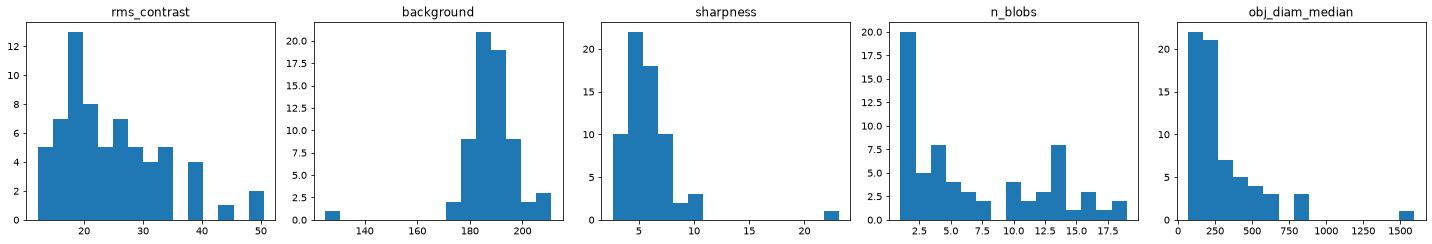

In [6]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.5))
for a, col in zip(ax, ["rms_contrast", "background", "sharpness", "n_blobs", "obj_diam_median"]):
    a.hist(stats[col], bins=15)
    a.set_title(col)
plt.tight_layout()
save_fig(fig, f"{OUT}/analysis/hist.png")
plt.show()

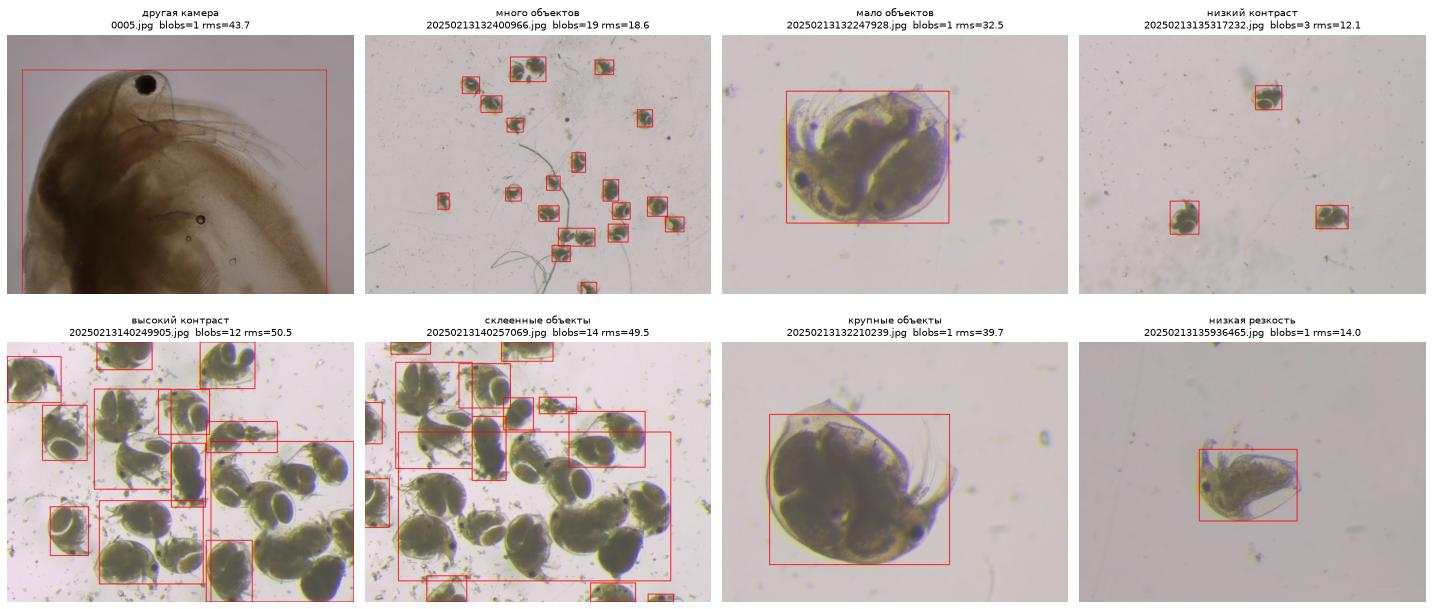

In [7]:
main = stats[stats.w == 2048]
picks = {"другая камера": stats.loc[stats.w != 2048].image.iloc[0]}
for title, col, asc in [("много объектов", "n_blobs", False), ("мало объектов", "n_blobs", True),
                        ("низкий контраст", "rms_contrast", True), ("высокий контраст", "rms_contrast", False),
                        ("склеенные объекты", "merged_blobs", False), ("крупные объекты", "obj_diam_median", False),
                        ("низкая резкость", "sharpness", True)]:
    order = main.sort_values(col, ascending=asc).image
    picks[title] = next(x for x in order if x not in picks.values())
fig, ax = plt.subplots(2, 4, figsize=(20, 9))
for a, (title, name) in zip(ax.ravel(), picks.items()):
    img = load(name)
    vis = rgb(img).copy()
    for b in blobs(img):
        x1, y1, x2, y2 = map(int, b["box"])
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 4)
    a.imshow(vis)
    s = stats.set_index("image").loc[name]
    a.set_title(f"{title}\n{name}  blobs={int(s.n_blobs)} rms={s.rms_contrast:.1f}", fontsize=10)
    a.axis("off")
plt.tight_layout()
save_fig(fig, f"{OUT}/analysis/examples.png")
plt.show()

- 65 снимков 2048x1536 и `0005.jpg` 2592x1944 с другой камеры (крупный план одного рачка, не влезает в кадр).
- Фон светлый и ровный (медиана ~188), организмы темнее фона.
- Контраст RMS от 12 до 50: низкий на разреженных снимках с мелкими полупрозрачными рачками, высокий на плотных.
- Снимки мыльные (дисперсия лапласиана 3-10), щетинки и антенны еле видны.
- От 1 до 19 объектов на кадр, диаметр ~70-850 px.
- На плотных снимках рачки касаются и перекрываются, порог их склеивает. Много мусора и волокон.

### 1.2 Аугментации

Яркость, контраст, гауссов шум (seed фиксирован), размытие, гамма, поворот (углы заливаются цветом фона), отражение, масштаб. У каждой по 4 уровня.

In [8]:
def border_color(img):
    b = np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])
    return tuple(int(v) for v in np.median(b, axis=0))


def brightness(img, beta):
    return np.clip(img.astype(np.float32) + beta, 0, 255).astype(np.uint8)


def contrast(img, alpha):
    return np.clip((img.astype(np.float32) - 128) * alpha + 128, 0, 255).astype(np.uint8)


def noise(img, sigma, seed=SEED):
    rng = np.random.default_rng(seed)
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)


def blur(img, k):
    return cv2.GaussianBlur(img, (k, k), 0)


def gamma(img, g):
    lut = (np.linspace(0, 1, 256) ** g * 255).astype(np.uint8)
    return cv2.LUT(img, lut)


def rotate(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1)
    return cv2.warpAffine(img, M, (w, h), borderValue=border_color(img))


def hflip(img):
    return cv2.flip(img, 1)


def rot90(img):
    return cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)


def scale(img, s):
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)

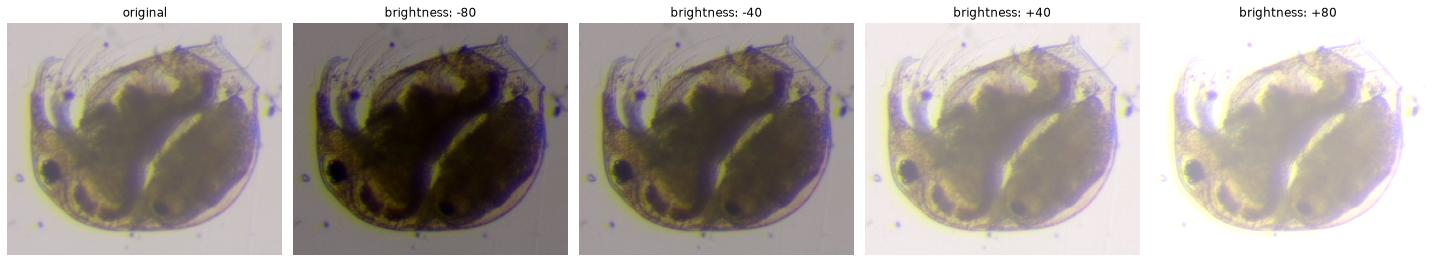

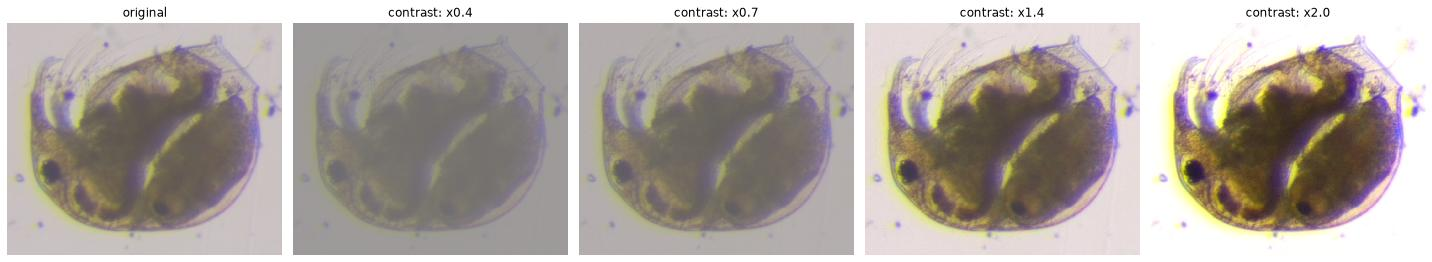

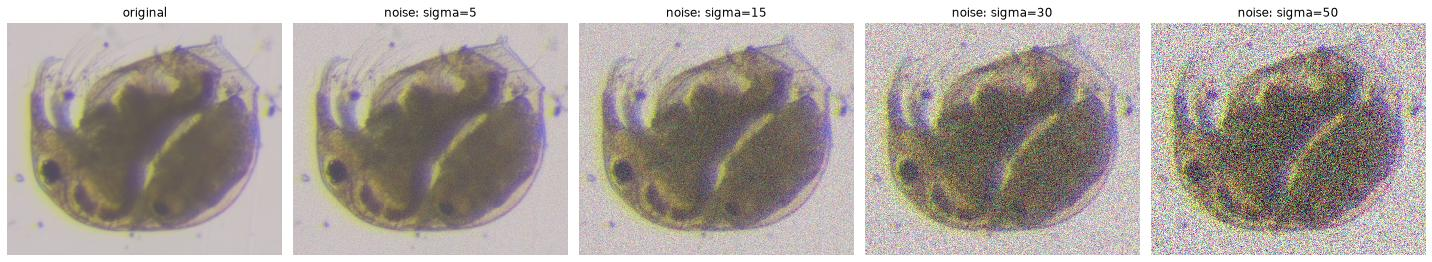

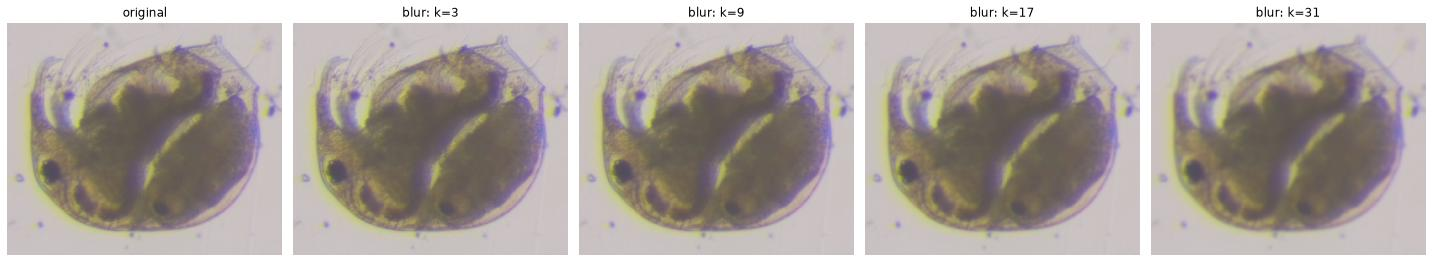

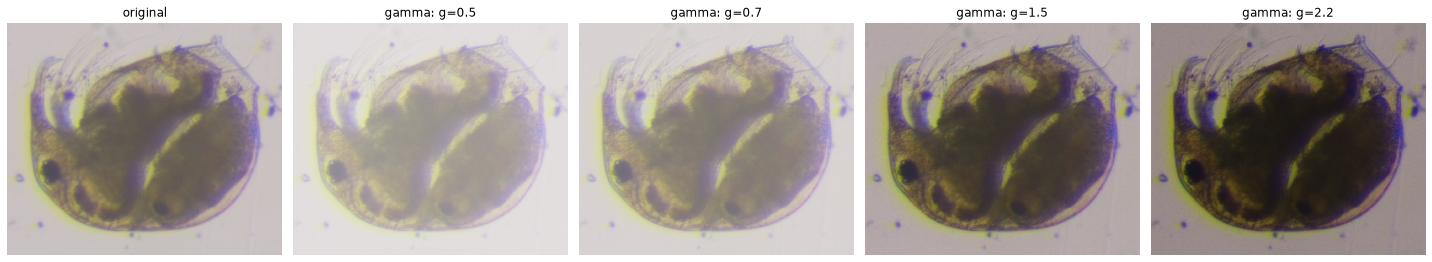

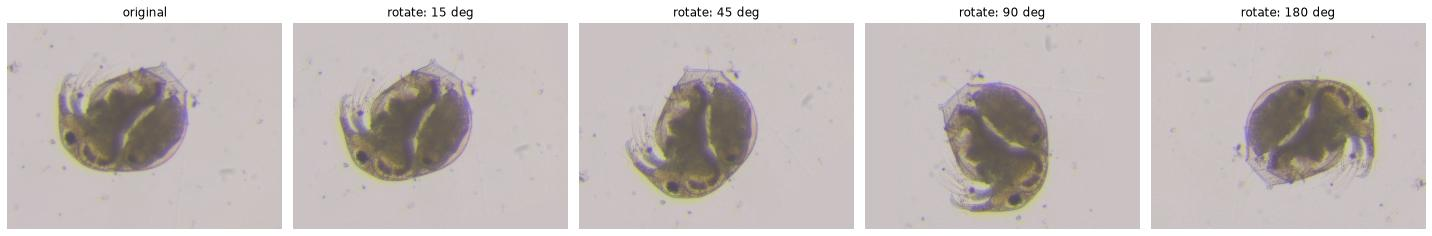

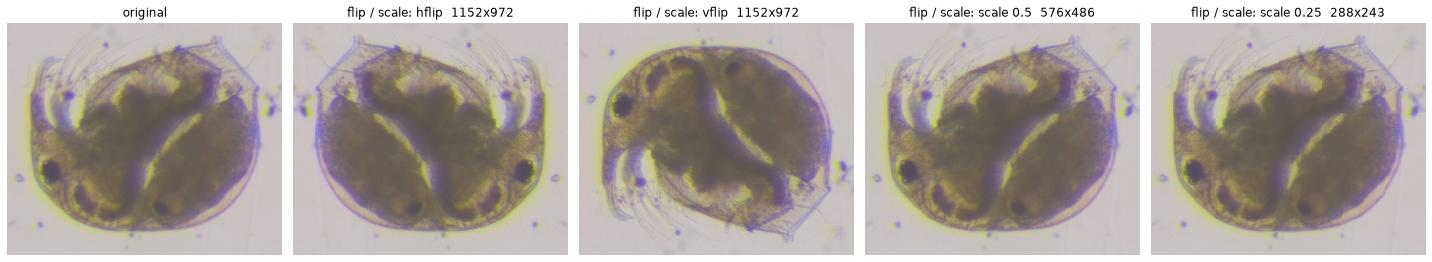

In [9]:
LEVELS = {
    "brightness": [(f"{b:+d}", lambda im, b=b: brightness(im, b)) for b in [-80, -40, 40, 80]],
    "contrast": [(f"x{a}", lambda im, a=a: contrast(im, a)) for a in [0.4, 0.7, 1.4, 2.0]],
    "noise": [(f"sigma={s}", lambda im, s=s: noise(im, s)) for s in [5, 15, 30, 50]],
    "blur": [(f"k={k}", lambda im, k=k: blur(im, k)) for k in [3, 9, 17, 31]],
    "gamma": [(f"g={g}", lambda im, g=g: gamma(im, g)) for g in [0.5, 0.7, 1.5, 2.2]],
    "rotate": [(f"{a} deg", lambda im, a=a: rotate(im, a)) for a in [15, 45, 90, 180]],
    "flip / scale": [("hflip", hflip), ("vflip", lambda im: cv2.flip(im, 0)),
                     ("scale 0.5", lambda im: scale(im, 0.5)), ("scale 0.25", lambda im: scale(im, 0.25))],
}

demo_name = picks["мало объектов"]
demo = load(demo_name)
x1, y1, x2, y2 = map(int, max(blobs(demo), key=lambda x: x["area"])["box"])
p = int(0.1 * max(x2 - x1, y2 - y1))
crop = demo[max(0, y1 - p):y2 + p, max(0, x1 - p):x2 + p]

for name, levels in LEVELS.items():
    src = demo if name == "rotate" else crop
    fig, ax = plt.subplots(1, 5, figsize=(20, 4.2))
    ax[0].imshow(rgb(src))
    ax[0].set_title("original")
    for a, (lvl, f) in zip(ax[1:], levels):
        out = f(src)
        a.imshow(rgb(out), interpolation="nearest")
        a.set_title(f"{name}: {lvl}  {out.shape[1]}x{out.shape[0]}" if name == "flip / scale" else f"{name}: {lvl}")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    save_fig(fig, f"{OUT}/aug/{name.replace(' / ', '_')}.png")
    plt.show()

Метрики на фрагменте с организмом (std, резкость относительно оригинала, доля краёв, PSNR) и число пятен по порогу из 1.1 на 7 снимках-примерах.

In [10]:
def crop_metrics(x, ref):
    g = cv2.cvtColor(x, cv2.COLOR_BGR2GRAY)
    gr = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    mse = ((g.astype(np.float32) - gr) ** 2).mean()
    return {
        "std": g.std(),
        "sharpness_rel": cv2.Laplacian(g, cv2.CV_64F).var() / cv2.Laplacian(gr, cv2.CV_64F).var(),
        "edges": (cv2.Canny(g, 50, 150) > 0).mean(),
        "psnr": 10 * np.log10(255 ** 2 / mse) if mse > 0 else np.inf,
    }


blob_set = [load(x) for x in picks.values() if x in main.image.values]
rows = [{"aug": "original", "level": "", **crop_metrics(crop, crop), "n_blobs": sum(len(blobs(x)) for x in blob_set)}]
for name in ["brightness", "contrast", "noise", "blur", "gamma"]:
    for lvl, f in LEVELS[name]:
        rows.append({"aug": name, "level": lvl, **crop_metrics(f(crop), crop), "n_blobs": sum(len(blobs(f(x))) for x in blob_set)})
aug_metrics = pd.DataFrame(rows)
aug_metrics.to_csv(f"{OUT}/aug/metrics.csv", index=False)
aug_metrics.round(3)

,aug,level,std,sharpness_rel,edges,psnr,n_blobs
0,original,,42.140,1.000,0.000,inf,51
1,brightness,-80,42.128,0.998,0.000,10.070,51
2,brightness,-40,42.140,1.000,0.000,16.090,51
3,brightness,+40,42.140,1.000,0.000,16.090,53
4,brightness,+80,33.566,0.614,0.000,11.026,63
5,contrast,x0.4,16.868,0.364,0.000,18.677,51
6,contrast,x0.7,29.509,0.694,0.000,24.623,51
7,contrast,x1.4,59.026,2.207,0.000,22.333,52
8,contrast,x2.0,80.602,2.943,0.004,15.232,56
9,noise,sigma=5,42.269,42.217,0.000,37.494,51


Геометрия безопасна: под микроскопом у организма нет верха и низа. Уменьшение в 2 раза почти ничего не меняет, при 0.25 щетинки пропадают.

- яркость +-40 просто сдвиг, при +80 фон упирается в 255 и порог находит 63 пятна вместо 51
- контраст 0.7-1.4 нормально, при 0.4 прозрачный панцирь сливается с фоном (резкость 0.36), при 2.0 фон белый и по краю жёлтый ореол
- шум с sigma 30 топит щетинки
- размытие хуже всего: k=3 уже вдвое снижает резкость, к k=17 щетинок и края панциря нет, остаётся силуэт
- гамма 2.2 делает тело чёрным, глаз и кишечник сливаются

Допустимо: отражения, повороты, масштаб 0.5-1.5, яркость +-40, контраст 0.7-1.4, гамма 0.7-1.5, слабый шум, размытие до k=3. Остальное убивает щетинки и антенны, по которым различают виды.

## 2. Детекция

### Выбор моделей

YOLO11 - одноэтапный. Backbone, neck (FPN/PAN) и голова, которая на каждой ячейке сетки сразу предсказывает бокс (без якорей) и класс, потом NMS. Один проход, поэтому быстро.

Faster R-CNN ResNet50-FPN v2 - двухэтапный. Сначала RPN по якорям предлагает ~1000 регионов, потом RoIAlign вырезает их признаки и вторая голова уточняет бокс и класс. Медленнее, зато каждый кандидат проверяется отдельно, и вход больше (короткая сторона 800).

Взял их как самых типичных представителей двух подходов, обе есть с весами COCO в ultralytics и torchvision.

Класса планктон в COCO нет, так что классы не важны, любой бокс считаю объектом. Порог 0.05 и NMS одинаковые для обеих, боксы больше 80% кадра выкидываю.

In [11]:
CONF = 0.05
NMS_IOU = 0.5
MAX_AREA = 0.8
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
YOLO_W = "yolo11m.pt"
YOLO_SIZE = 1024

yolo = YOLO(f"weights/{YOLO_W}")
frcnn_w = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
frcnn = fasterrcnn_resnet50_fpn_v2(weights=frcnn_w, box_score_thresh=0.01).eval().to(DEVICE)
CATS = frcnn_w.meta["categories"]

In [12]:
def postprocess(boxes, scores, labels, shape):
    h, w = shape[:2]
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    m = (scores >= CONF) & (area < MAX_AREA * h * w)
    boxes, scores, labels = boxes[m], scores[m], labels[m]
    keep = torchvision.ops.nms(torch.tensor(boxes), torch.tensor(scores), NMS_IOU).numpy()
    return boxes[keep], scores[keep], labels[keep]


def run_yolo(img):
    t = time.perf_counter()
    r = yolo.predict(img, imgsz=YOLO_SIZE, conf=0.01, iou=0.7, agnostic_nms=True, verbose=False, device=DEVICE)[0]
    dt = time.perf_counter() - t
    labels = np.array([r.names[int(c)] for c in r.boxes.cls])
    return postprocess(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), labels, img.shape), dt


def run_frcnn(img):
    x = torch.from_numpy(rgb(img)).permute(2, 0, 1).float() / 255
    t = time.perf_counter()
    with torch.no_grad():
        p = frcnn([x.to(DEVICE)])[0]
        p = {k: v.cpu().numpy() for k, v in p.items()}
    dt = time.perf_counter() - t
    labels = np.array([CATS[i] for i in p["labels"]])
    return postprocess(p["boxes"], p["scores"], labels, img.shape), dt


MODELS = {"yolo11": run_yolo, "faster_rcnn": run_frcnn}

warm = load(files[0])
for f in MODELS.values():
    f(warm)

In [13]:
def draw(img, boxes, scores, color=(255, 0, 0), thick=4):
    vis = rgb(img).copy()
    fs = img.shape[1] / 1600
    for (x1, y1, x2, y2), s in zip(boxes.astype(int), scores):
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, thick)
        cv2.putText(vis, f"{s:.2f}", (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, fs, color, 2)
    return vis

### Аугментации для экспериментов 2 и 4

5 фотометрических и 3 геометрических, одинаковые для обеих моделей. Шум, размытие и контраст взял жёстче допустимого, чтобы была видна разница. Для геометрии боксы переводятся обратно в координаты оригинала.

In [14]:
DET_AUGS = {
    "contrast_0.6": lambda im: contrast(im, 0.6),
    "brightness_+40": lambda im: brightness(im, 40),
    "gamma_1.5": lambda im: gamma(im, 1.5),
    "noise_20": lambda im: noise(im, 20),
    "blur_9": lambda im: blur(im, 9),
    "hflip": hflip,
    "rot90": rot90,
    "scale_0.5": lambda im: scale(im, 0.5),
}


def unmap(boxes, aug, shape):
    h, w = shape[:2]
    b = boxes.copy()
    if aug == "hflip":
        b[:, 0], b[:, 2] = w - boxes[:, 2], w - boxes[:, 0]
    elif aug == "rot90":
        b[:, 0], b[:, 2] = boxes[:, 1], boxes[:, 3]
        b[:, 1], b[:, 3] = h - boxes[:, 2], h - boxes[:, 0]
    elif aug == "scale_0.5":
        b = boxes / 0.5
    return b

### Эксперименты

| # | модель | данные |
|---|---|---|
| 1 | YOLO11 | исходные 66 снимков |
| 2 | YOLO11 | 66 снимков x 8 аугментаций |
| 3 | Faster R-CNN | исходные 66 снимков |
| 4 | Faster R-CNN | 66 снимков x 8 аугментаций |

MacBook Air M2, MPS, первый прогон прогревочный.

In [15]:
det_rows, time_rows = [], []
for name in files:
    img = load(name)
    variants = [("original", img)] + [(a, f(img)) for a, f in DET_AUGS.items()]
    for aug, im in variants:
        for model, run in MODELS.items():
            (boxes, scores, labels), dt = run(im)
            exp = {"yolo11": 1, "faster_rcnn": 3}[model] + (aug != "original")
            back = unmap(boxes, aug, img.shape) if len(boxes) else boxes
            time_rows.append({"exp": exp, "model": model, "aug": aug, "image": name,
                              "time_s": dt, "n_det": len(boxes)})
            for bx, ob, s, l in zip(boxes, back, scores, labels):
                det_rows.append({"exp": exp, "model": model, "aug": aug, "image": name,
                                 "x1": bx[0], "y1": bx[1], "x2": bx[2], "y2": bx[3],
                                 "ox1": ob[0], "oy1": ob[1], "ox2": ob[2], "oy2": ob[3],
                                 "score": s, "coco_class": l})


def group_flags(b, k=2, thr=0.9):
    if len(b) <= k:
        return np.zeros(len(b), bool)
    lt = np.maximum(b[:, None, :2], b[None, :, :2])
    rb = np.minimum(b[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area = (b[:, 2:] - b[:, :2]).prod(-1)
    inside = inter / area[None, :] >= thr
    np.fill_diagonal(inside, False)
    return inside.sum(1) >= k


dets = pd.DataFrame(det_rows).round(2)
dets["group"] = False
for _, g in dets.groupby(["model", "aug", "image"]):
    dets.loc[g.index, "group"] = group_flags(g[["x1", "y1", "x2", "y2"]].to_numpy())
times = pd.DataFrame(time_rows)
dets.to_csv(f"{OUT}/detection/detections.csv", index=False)
times.to_csv(f"{OUT}/detection/timing.csv", index=False)

In [16]:
def boxes_of(model, aug, name, col="o"):
    d = dets[(dets.model == model) & (dets.aug == aug) & (dets.image == name)]
    cols = [f"{col}x1", f"{col}y1", f"{col}x2", f"{col}y2"] if col else ["x1", "y1", "x2", "y2"]
    return d[cols].to_numpy(), d.score.to_numpy()


exp_summary = []
for (exp, model), g in times.groupby(["exp", "model"]):
    d = dets[dets.exp == exp]
    exp_summary.append({
        "exp": exp, "model": model, "data": "original" if exp in (1, 3) else "augmented",
        "input": f"{YOLO_SIZE} (long side)" if model == "yolo11" else "800 (short side)", "device": DEVICE,
        "conf": CONF, "images": len(g),
        "time_mean_s": g.time_s.mean(), "time_median_s": g.time_s.median(),
        "det_total": g.n_det.sum(), "det_per_img": g.n_det.mean(),
        "zero_det_imgs": (g.n_det == 0).sum(),
        "group_boxes": d.group.sum(),
        "score_mean": d.score.mean(), "score_median": d.score.median(),
    })
exp_summary = pd.DataFrame(exp_summary)
exp_summary.round(3)

,exp,model,data,input,device,conf,images,time_mean_s,time_median_s,det_total,det_per_img,zero_det_imgs,group_boxes,score_mean,score_median
0,1,yolo11,original,1024 (long side),mps,0.05,66,0.116,0.116,753,11.409,1,21,0.168,0.110
1,2,yolo11,augmented,1024 (long side),mps,0.05,528,0.112,0.108,5492,10.402,13,189,0.176,0.120
2,3,faster_rcnn,original,800 (short side),mps,0.05,66,0.468,0.454,538,8.152,0,37,0.316,0.195
3,4,faster_rcnn,augmented,800 (short side),mps,0.05,528,0.473,0.454,3979,7.536,7,355,0.308,0.190


YOLO примерно в 4 раза быстрее (0.12 с против 0.47 с на кадр). Уверенность низкая у обеих (медиана 0.11 и 0.2), классы случайные. Боксов у YOLO больше за счёт мусора, на одном снимке 59.

In [17]:
dets[dets.aug == "original"].groupby(["model", "coco_class"]).size().sort_values(ascending=False).groupby(level=0).head(6)

model        coco_class
yolo11       kite          473
             apple         178
faster_rcnn  kite          158
             bird          133
yolo11       bird           70
faster_rcnn  broccoli       42
             apple          33
             cake           25
             bowl           24
yolo11       spoon           5
             vase            5
             cat             4
dtype: int64

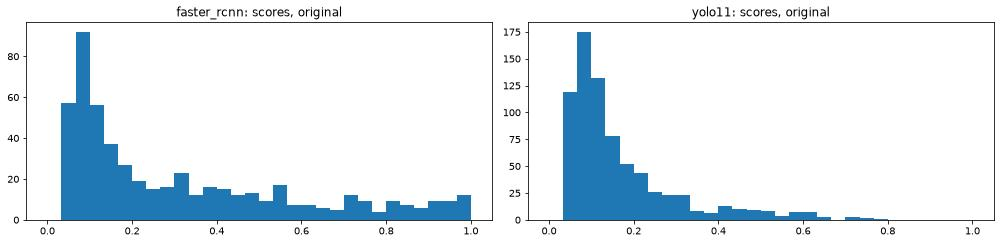

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for a, (model, g) in zip(ax, dets[dets.aug == "original"].groupby("model")):
    a.hist(g.score, bins=30, range=(0, 1))
    a.set_title(f"{model}: scores, original")
plt.tight_layout()
save_fig(fig, f"{OUT}/detection/scores_hist.png")
plt.show()

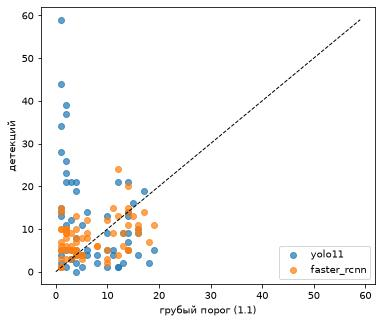

In [19]:
cmp = times[times.aug == "original"].pivot(index="image", columns="model", values="n_det")
cmp["blobs"] = stats.set_index("image").n_blobs
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(cmp.blobs, cmp.yolo11, label="yolo11", alpha=0.7)
ax.scatter(cmp.blobs, cmp.faster_rcnn, label="faster_rcnn", alpha=0.7)
mx = cmp.max().max()
ax.plot([0, mx], [0, mx], "k--", lw=1)
ax.set_xlabel("грубый порог (1.1)")
ax.set_ylabel("детекций")
ax.legend()
save_fig(fig, f"{OUT}/detection/count_vs_blobs.png")
plt.show()

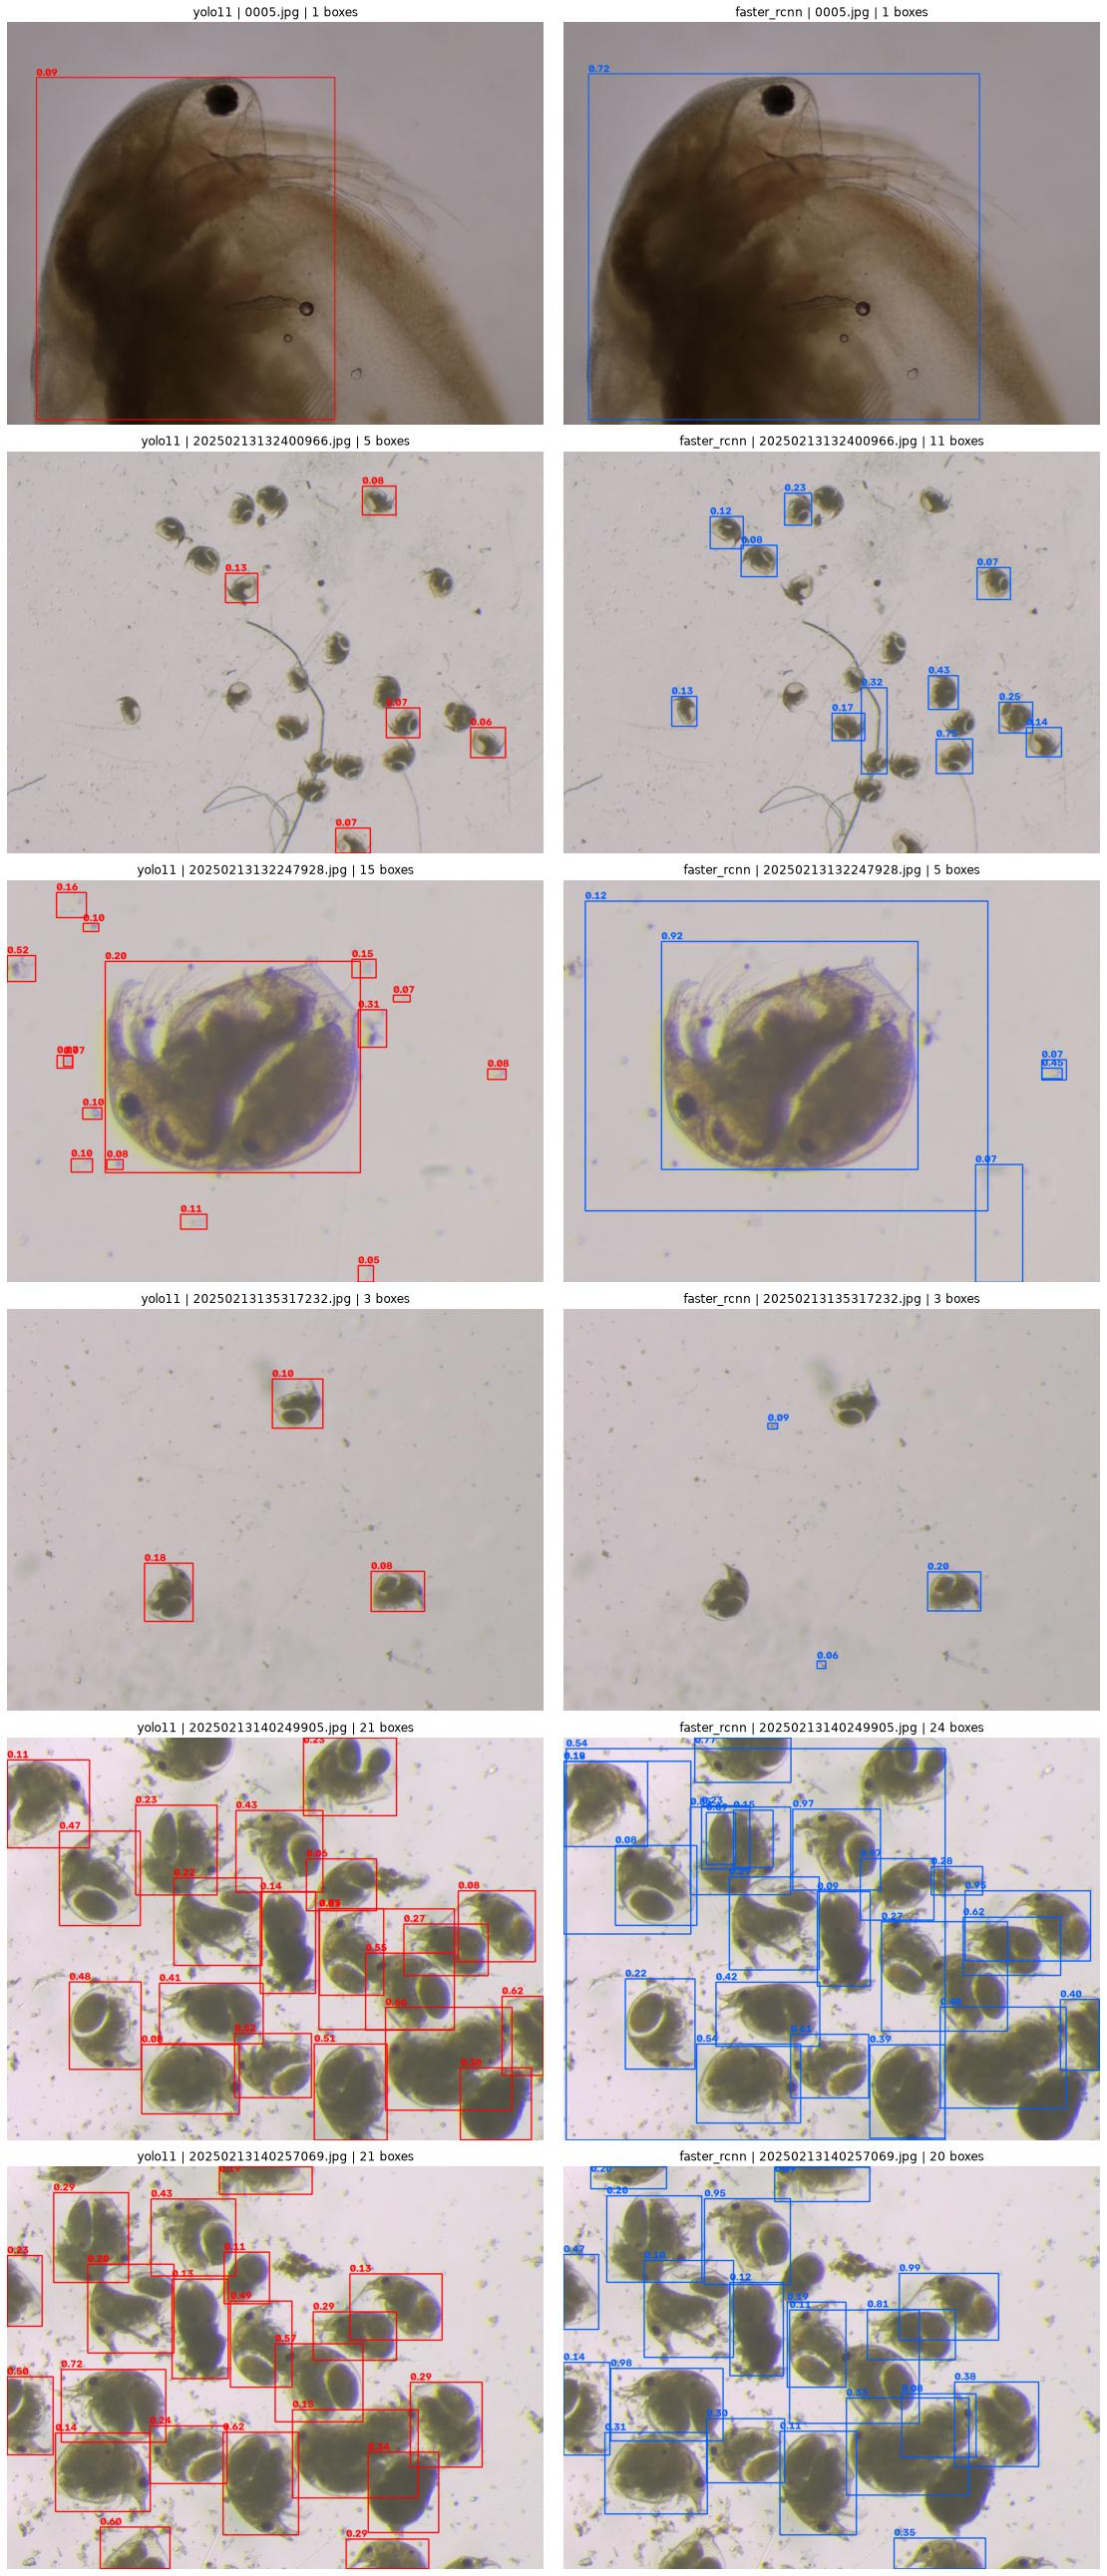

In [20]:
os.makedirs(f"{OUT}/detection/yolo11", exist_ok=True)
os.makedirs(f"{OUT}/detection/faster_rcnn", exist_ok=True)
for name in files:
    img = load(name)
    for model, color in [("yolo11", (255, 0, 0)), ("faster_rcnn", (0, 90, 255))]:
        b, s = boxes_of(model, "original", name, col="")
        vis = draw(img, b, s, color)
        vis = cv2.resize(vis, None, fx=1024 / vis.shape[1], fy=1024 / vis.shape[1], interpolation=cv2.INTER_AREA)
        cv2.imwrite(f"{OUT}/detection/{model}/{name}", cv2.cvtColor(vis, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 80])

show_imgs = list(dict.fromkeys(picks.values()))[:6]
fig, ax = plt.subplots(len(show_imgs), 2, figsize=(16, 6 * len(show_imgs)))
for i, name in enumerate(show_imgs):
    img = load(name)
    for j, (model, color) in enumerate([("yolo11", (255, 0, 0)), ("faster_rcnn", (0, 90, 255))]):
        b, s = boxes_of(model, "original", name, col="")
        ax[i, j].imshow(draw(img, b, s, color))
        ax[i, j].set_title(f"{model} | {name} | {len(b)} boxes")
        ax[i, j].axis("off")
plt.tight_layout()
save_fig(fig, f"{OUT}/detection/originals_grid.png")
plt.show()

По картинкам (все 66 снимков с боксами в `results/detection/`):
- крупных рачков находят обе, но на `0005.jpg` у YOLO всего 0.09
- мелких на разреженных снимках пропускают: на `...132400966` из ~19 YOLO нашла 5, Faster R-CNN 11
- на бледном `...135317232` наоборот YOLO нашла всех троих, Faster R-CNN одного
- YOLO ставит много боксов на соринки (14 лишних на `...132247928`), у Faster R-CNN мусора меньше, но бывают боксы на весь фон
- на плотных снимках у Faster R-CNN много вложенных боксов и боксов на пару рачков

### Устойчивость к аугментациям

Боксы после аугментации (в координатах оригинала) жадно сопоставляю с боксами той же модели на оригинале по IoU >= 0.5.

In [21]:
def match(a, b, thr=0.5):
    if len(a) == 0 or len(b) == 0:
        return []
    iou = torchvision.ops.box_iou(torch.tensor(a), torch.tensor(b)).numpy()
    pairs = []
    while iou.size and iou.max() >= thr:
        i, j = np.unravel_index(iou.argmax(), iou.shape)
        pairs.append((i, j, iou[i, j]))
        iou[i, :] = -1
        iou[:, j] = -1
    return pairs


st_rows = []
for model in MODELS:
    for name in files:
        ref, _ = boxes_of(model, "original", name)
        for aug in DET_AUGS:
            cur, _ = boxes_of(model, aug, name)
            p = match(ref, cur)
            st_rows.append({"model": model, "aug": aug, "image": name, "n_orig": len(ref), "n_aug": len(cur),
                            "matched": len(p), "iou_sum": sum(x[2] for x in p)})
st = pd.DataFrame(st_rows)
stability = st.groupby(["model", "aug"]).sum(numeric_only=True)
stability["matched_share"] = stability.matched / stability.n_orig
stability["iou_mean"] = stability.iou_sum / stability.matched
stability["lost"] = stability.n_orig - stability.matched
stability["new"] = stability.n_aug - stability.matched
stability["count_change_%"] = (stability.n_aug / stability.n_orig - 1) * 100
stability = stability.drop(columns="iou_sum").reset_index()
stability.to_csv(f"{OUT}/detection/stability.csv", index=False)
stability.round(3)

,model,aug,n_orig,n_aug,matched,matched_share,iou_mean,lost,new,count_change_%
0,faster_rcnn,blur_9,538,429,351,0.652,0.904,187,78,-20.260
1,faster_rcnn,brightness_+40,538,430,351,0.652,0.906,187,79,-20.074
2,faster_rcnn,contrast_0.6,538,413,353,0.656,0.911,185,60,-23.234
3,faster_rcnn,gamma_1.5,538,569,453,0.842,0.920,85,116,5.762
4,faster_rcnn,hflip,538,510,366,0.680,0.882,172,144,-5.204
5,faster_rcnn,noise_20,538,575,275,0.511,0.852,263,300,6.877
6,faster_rcnn,rot90,538,567,318,0.591,0.865,220,249,5.390
7,faster_rcnn,scale_0.5,538,486,442,0.822,0.937,96,44,-9.665
8,yolo11,blur_9,753,755,613,0.814,0.943,140,142,0.266
9,yolo11,brightness_+40,753,734,628,0.834,0.952,125,106,-2.523


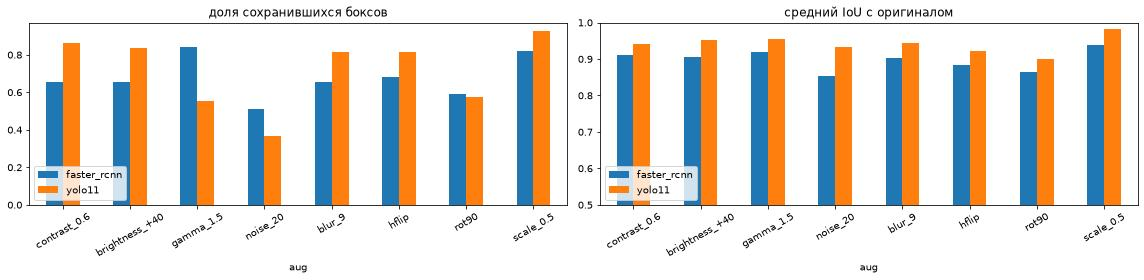

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
piv = stability.pivot(index="aug", columns="model", values="matched_share").loc[list(DET_AUGS)]
piv.plot.bar(ax=ax[0], rot=30, title="доля сохранившихся боксов")
ax[0].legend(loc="lower left")
piv = stability.pivot(index="aug", columns="model", values="iou_mean").loc[list(DET_AUGS)]
piv.plot.bar(ax=ax[1], rot=30, title="средний IoU с оригиналом", ylim=(0.5, 1))
ax[1].legend(loc="lower left")
plt.tight_layout()
save_fig(fig, f"{OUT}/detection/stability.png")
plt.show()

Если объект нашёлся снова, бокс почти тот же (IoU 0.85-0.98), меняется в основном то, что проходит порог. Даже после отражения остаётся 68% боксов Faster R-CNN и 82% YOLO.

YOLO устойчивее к яркости, контрасту и размытию, но на шуме теряет 63% боксов. У Faster R-CNN шум тоже худший случай: половина боксов пропадает, 300 новых появляется. rot90 плохо обеим (~58%), scale 0.5 почти ничего не меняет.

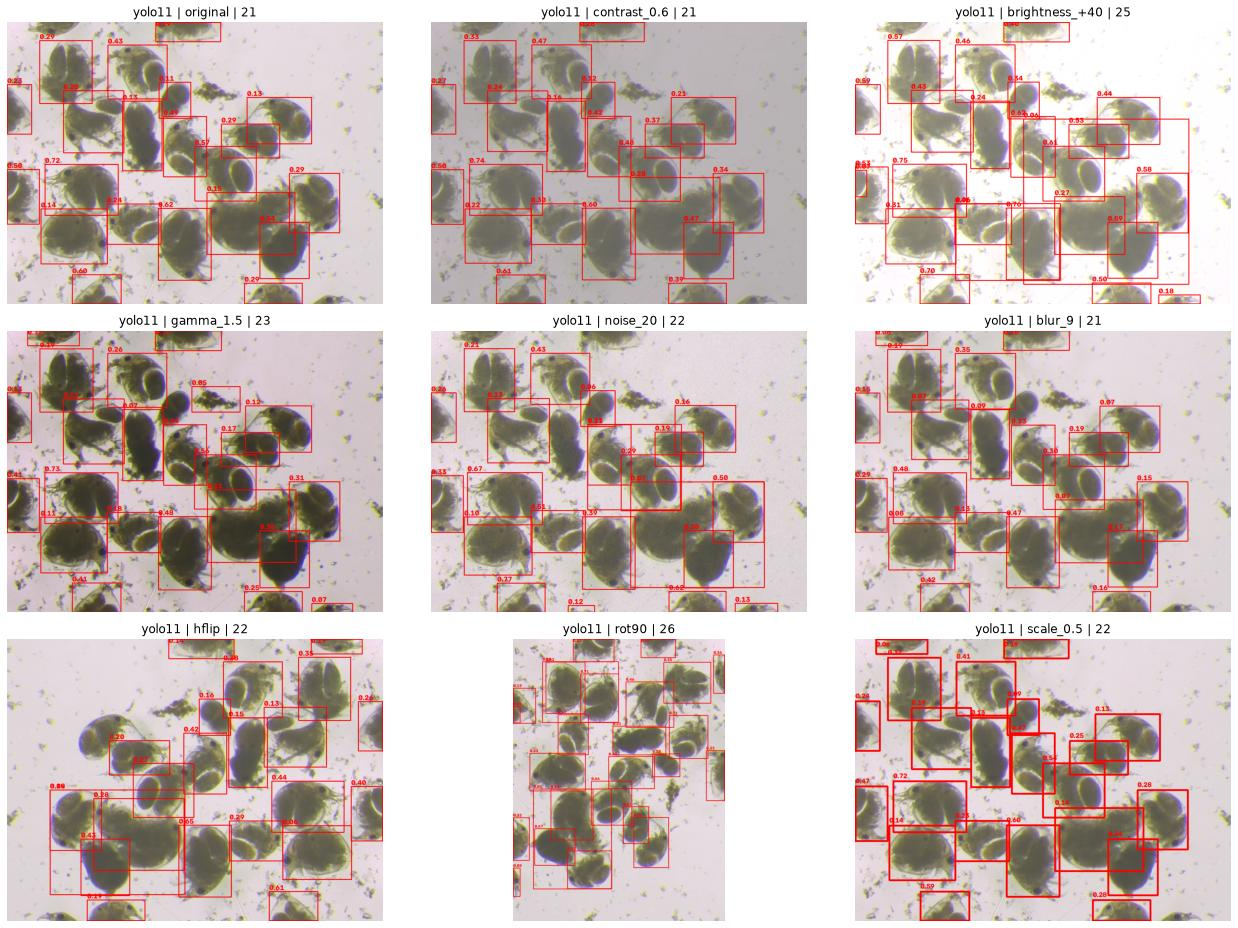

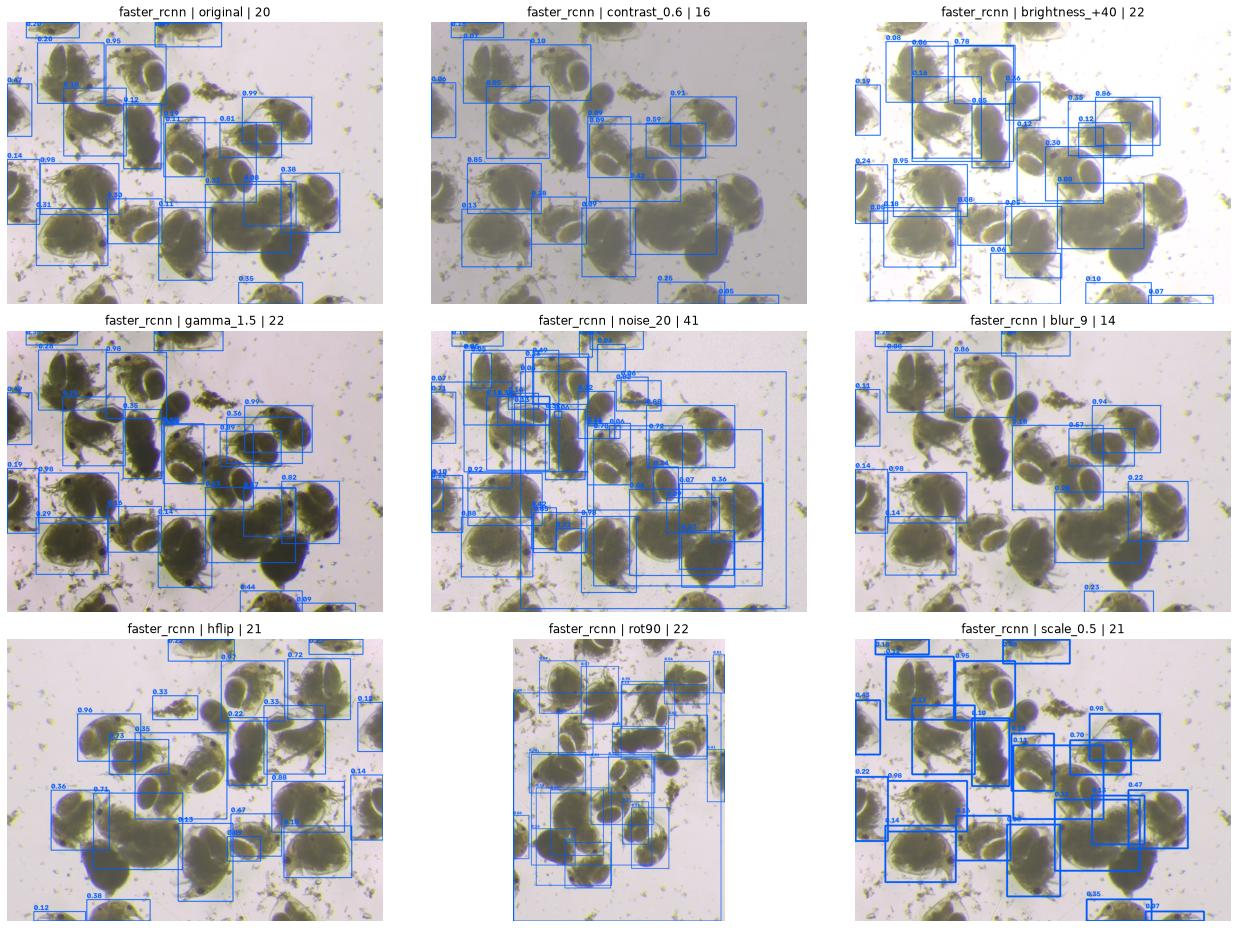

In [23]:
aug_demo = picks["склеенные объекты"]
img = load(aug_demo)
for model, color in [("yolo11", (255, 0, 0)), ("faster_rcnn", (0, 90, 255))]:
    fig, ax = plt.subplots(3, 3, figsize=(18, 13))
    for a, aug in zip(ax.ravel(), ["original"] + list(DET_AUGS)):
        im = img if aug == "original" else DET_AUGS[aug](img)
        b, s = boxes_of(model, aug, aug_demo, col="")
        a.imshow(draw(im, b, s, color, thick=3))
        a.set_title(f"{model} | {aug} | {len(b)}")
        a.axis("off")
    plt.tight_layout()
    save_fig(fig, f"{OUT}/detection/aug_{model}.png")
    plt.show()

### Какой детектор лучше

Faster R-CNN: больше настоящих рачков, особенно мелких (11 против 5 на `...132400966`, 7 против 2 на `...135439391`), меньше мусора, на крупных уверенность 0.7-0.99. Минусы: в 4 раза медленнее, больше вложенных боксов, на шуме ставит сотни ложных. Для 66 снимков скорость не важна, поэтому дальше беру его боксы.

## 3. Сегментация

Боксы Faster R-CNN со score >= 0.2 без групповых (внутри которых 2+ других), 9 снимков разного типа. Сохраняются в `boxes.json`, оба метода читают один файл.

In [24]:
SEG_MODEL = "faster_rcnn"
SEG_CONF = 0.2
SEG_IMAGES = list(dict.fromkeys(list(picks.values()) + ["20250213132415074.jpg"]))
MANUAL = {}

seg_input = {}
for name in SEG_IMAGES:
    d = dets[(dets.model == SEG_MODEL) & (dets.aug == "original") & (dets.image == name) & (dets.score >= SEG_CONF)]
    d = d[~d.group]
    seg_input[name] = {"source": "detector", "boxes": d[["x1", "y1", "x2", "y2"]].to_numpy().tolist(),
                       "scores": d.score.tolist()}
    if name in MANUAL:
        seg_input[name] = {"source": "manual", "boxes": MANUAL[name], "scores": [1.0] * len(MANUAL[name])}
with open(f"{OUT}/segmentation/boxes.json", "w") as f:
    json.dump({"model": SEG_MODEL, "conf": SEG_CONF, "images": seg_input}, f, indent=1)

with open(f"{OUT}/segmentation/boxes.json") as f:
    seg_input = json.load(f)["images"]
{k: (v["source"], len(v["boxes"])) for k, v in seg_input.items()}

{'0005.jpg': ('detector', 1),
 '20250213132400966.jpg': ('detector', 5),
 '20250213132247928.jpg': ('detector', 2),
 '20250213135317232.jpg': ('detector', 1),
 '20250213140249905.jpg': ('detector', 16),
 '20250213140257069.jpg': ('detector', 12),
 '20250213132210239.jpg': ('detector', 3),
 '20250213135936465.jpg': ('detector', 6),
 '20250213132415074.jpg': ('detector', 8)}

Ручные боксы не понадобились, на всех 9 снимках детектор что-то нашёл.

### GrabCut

Область бокса с запасом 15%, инициализация прямоугольником, 5 итераций.

In [25]:
GC_MARGIN = 0.15
GC_ITERS = 5


def grabcut(img, box):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = box
    mx, my = (x2 - x1) * GC_MARGIN, (y2 - y1) * GC_MARGIN
    cx1, cy1 = int(max(0, x1 - mx)), int(max(0, y1 - my))
    cx2, cy2 = int(min(w, x2 + mx)), int(min(h, y2 + my))
    crop = img[cy1:cy2, cx1:cx2]
    rx, ry = int(x1) - cx1, int(y1) - cy1
    rw, rh = min(int(x2 - x1), crop.shape[1] - rx - 1), min(int(y2 - y1), crop.shape[0] - ry - 1)
    mask = np.zeros(crop.shape[:2], np.uint8)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(crop, mask, (rx, ry, rw, rh), bgd, fgd, GC_ITERS, cv2.GC_INIT_WITH_RECT)
    full = np.zeros((h, w), np.uint8)
    full[cy1:cy2, cx1:cx2] = np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD])
    return full


masks = {"grabcut": {}, "sam2": {}}
seg_times = []
for name, v in seg_input.items():
    img = load(name)
    out = []
    t0 = time.perf_counter()
    for b in v["boxes"]:
        out.append(grabcut(img, b))
    dt = time.perf_counter() - t0
    masks["grabcut"][name] = np.array(out).reshape(-1, *img.shape[:2])
    seg_times.append({"method": "grabcut", "image": name, "boxes": len(out), "time_s": dt})

### SAM 2

SAM 2.1 base из ultralytics, боксы как box prompts. `conf=0`, иначе ultralytics выкидывает часть масок.

In [26]:
sam = SAM("weights/sam2.1_b.pt")
sam(load(SEG_IMAGES[0]), bboxes=[[0, 0, 100, 100]], device=DEVICE, verbose=False, conf=0)

sam_scores = {}
for name, v in seg_input.items():
    img = load(name)
    m = np.zeros((len(v["boxes"]), *img.shape[:2]), np.uint8)
    s = np.zeros(len(v["boxes"]))
    t0 = time.perf_counter()
    if v["boxes"]:
        r = sam(img, bboxes=v["boxes"], device=DEVICE, verbose=False, conf=0)[0]
        idx = r.boxes.cls.cpu().numpy().astype(int)
        m[idx] = r.masks.data.cpu().numpy()
        s[idx] = r.boxes.conf.cpu().numpy()
    dt = time.perf_counter() - t0
    masks["sam2"][name] = m
    sam_scores[name] = s
    seg_times.append({"method": "sam2", "image": name, "boxes": len(v["boxes"]), "time_s": dt})
seg_times = pd.DataFrame(seg_times)

In [27]:
os.makedirs(f"{OUT}/segmentation/masks", exist_ok=True)
for method in masks:
    for name, m in masks[method].items():
        stem = name.rsplit(".", 1)[0]
        union = (m.max(0) if len(m) else np.zeros(load(name).shape[:2])) * 255
        cv2.imwrite(f"{OUT}/segmentation/masks/{stem}_{method}.png", union.astype(np.uint8))
        inst = np.zeros(union.shape, np.uint8)
        for i, x in enumerate(m):
            inst[(x > 0) & (inst == 0)] = i + 1
        cv2.imwrite(f"{OUT}/segmentation/masks/{stem}_{method}_inst.png", inst)

### Визуализация

Всё сохраняется в `results/segmentation/vis/` и `masks/`.

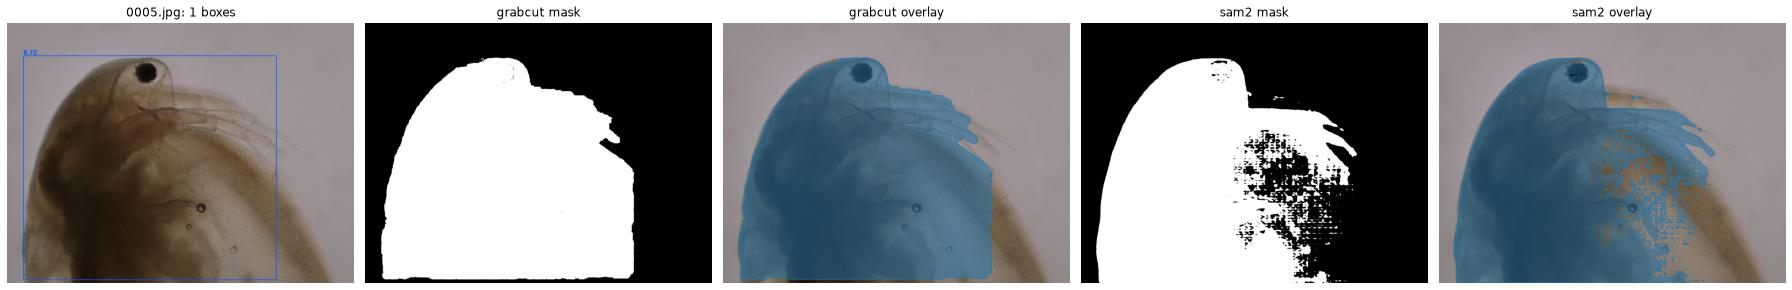

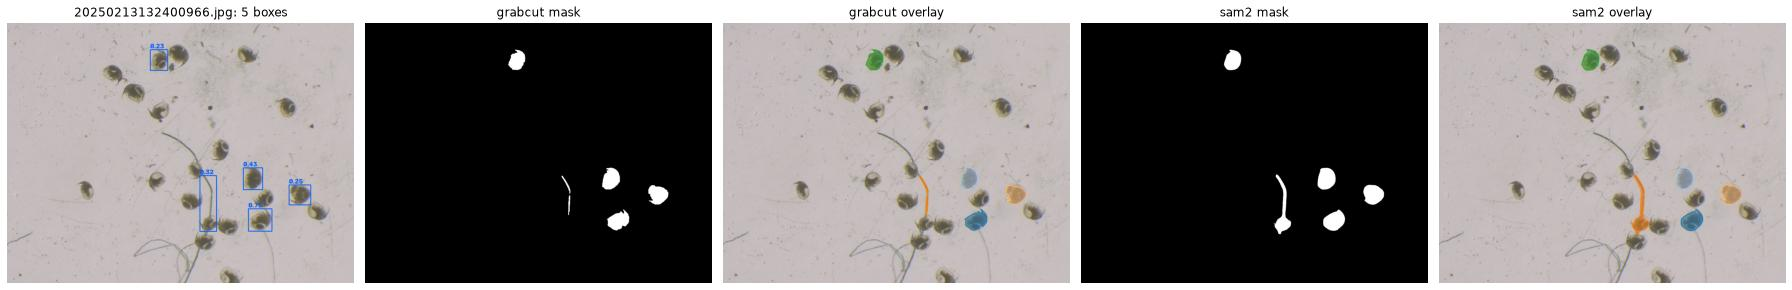

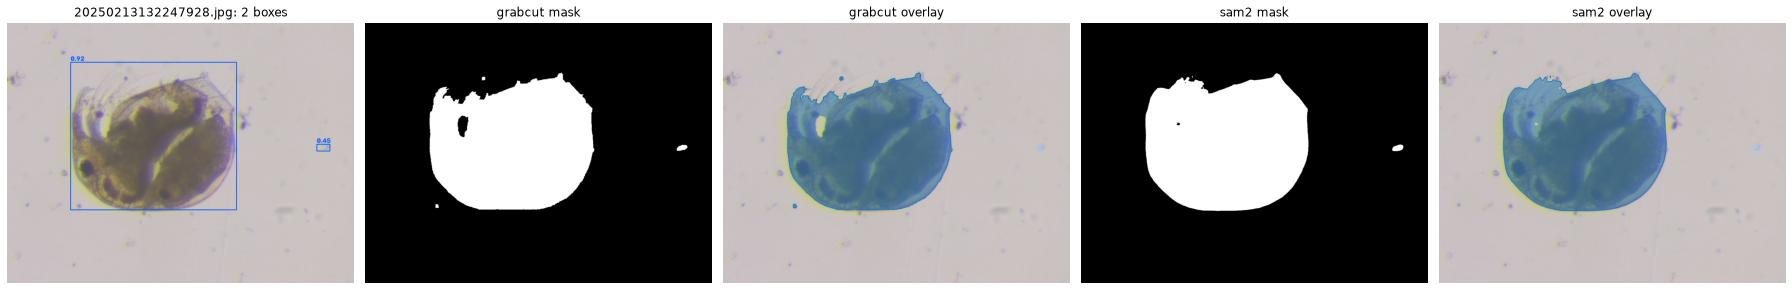

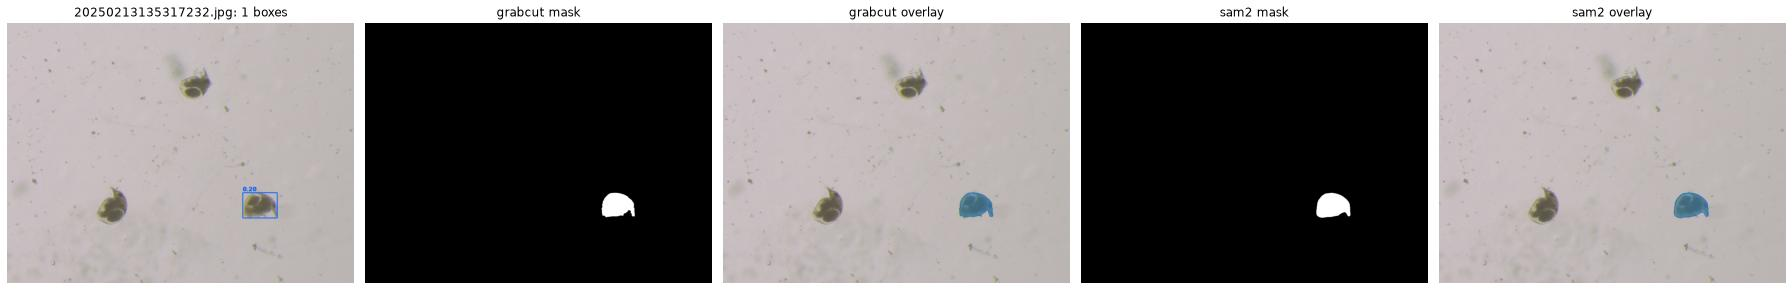

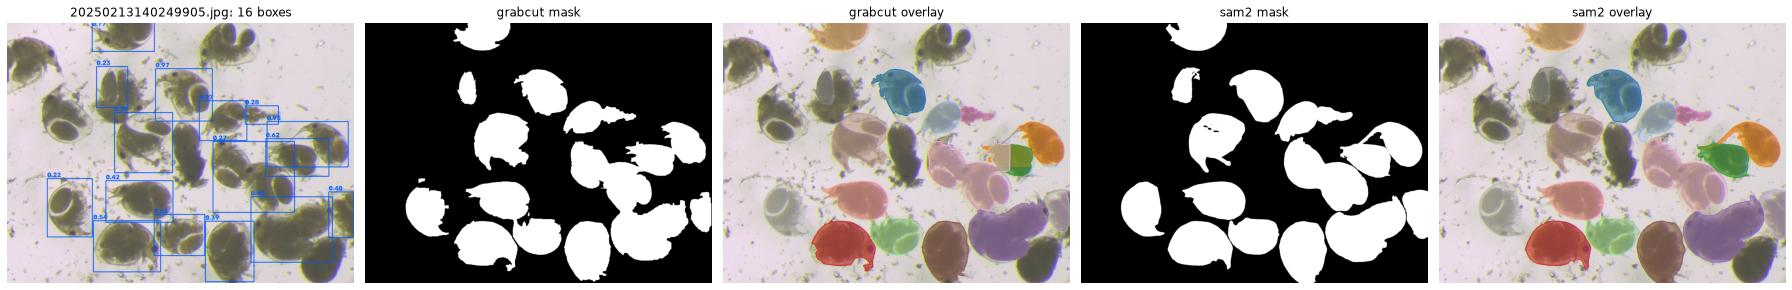

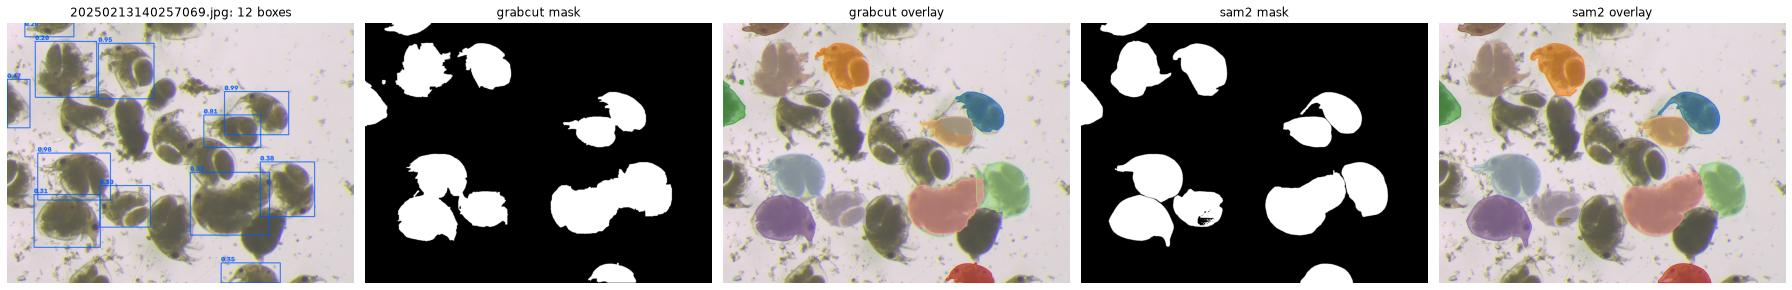

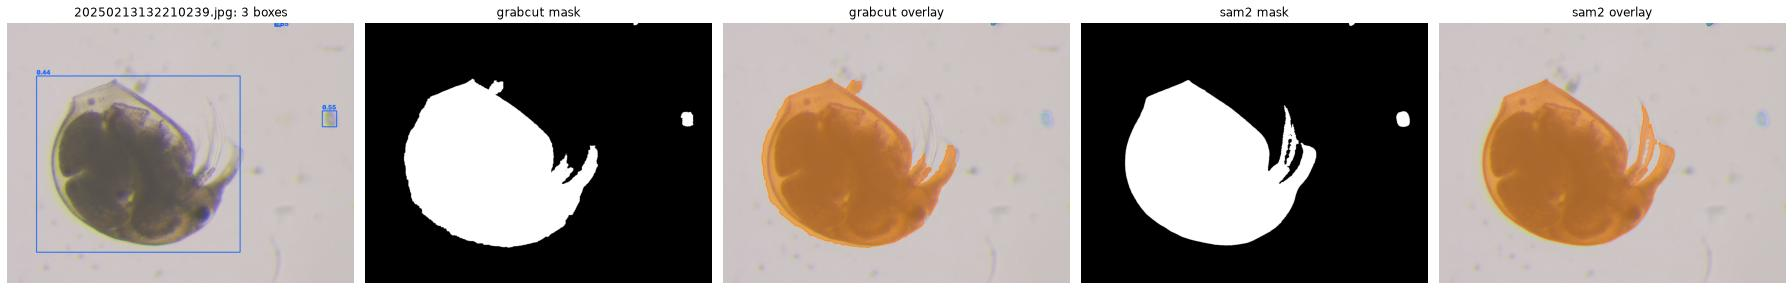

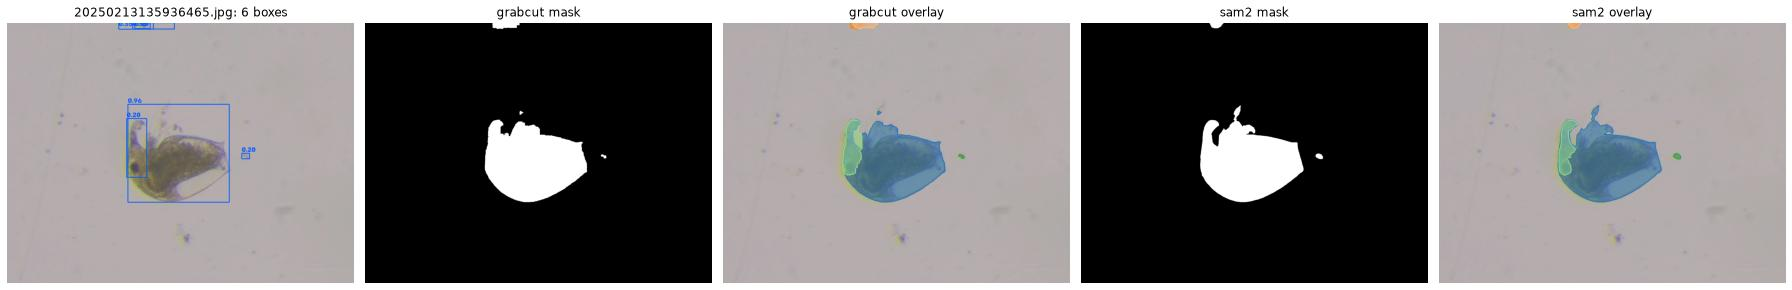

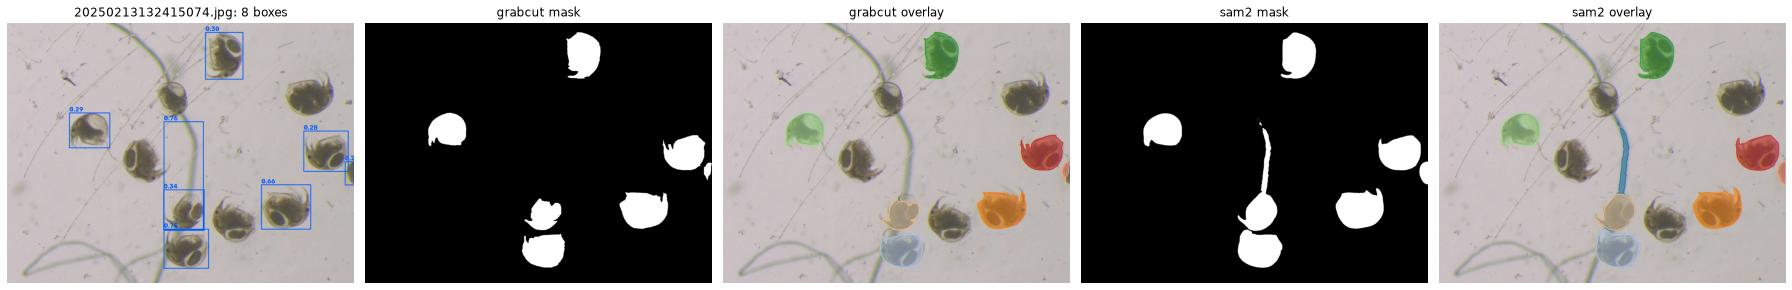

In [28]:
PALETTE = plt.cm.tab20(np.linspace(0, 1, 20))[:, :3] * 255


def overlay(img, m, alpha=0.5):
    vis = rgb(img).astype(np.float32)
    for i, x in enumerate(m):
        c = PALETTE[i % 20]
        vis[x > 0] = vis[x > 0] * (1 - alpha) + c * alpha
        cnts, _ = cv2.findContours(x.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cnts, -1, c.tolist(), 3)
    return vis.astype(np.uint8)


os.makedirs(f"{OUT}/segmentation/vis", exist_ok=True)
for name, v in seg_input.items():
    img = load(name)
    b = np.array(v["boxes"]).reshape(-1, 4)
    panels = [(f"{name}: {len(b)} boxes" + (" (manual)" if v["source"] == "manual" else ""),
               draw(img, b, np.array(v["scores"]), (0, 90, 255)))]
    for method in ["grabcut", "sam2"]:
        m = masks[method][name]
        panels.append((f"{method} mask", m.max(0) if len(m) else np.zeros(img.shape[:2])))
        panels.append((f"{method} overlay", overlay(img, m)))
    fig, ax = plt.subplots(1, 5, figsize=(25, 4.4))
    for a, (t, p) in zip(ax, panels):
        a.imshow(p, cmap="gray")
        a.set_title(t)
        a.axis("off")
    plt.tight_layout()
    save_fig(fig, f"{OUT}/segmentation/vis/{name.rsplit('.', 1)[0]}.jpg")
    plt.show()

- одиночные рачки нормально у обоих, но SAM 2 сохраняет щетинки (`...132210239`), GrabCut сливает их в пятно
- на плотных снимках SAM 2 разделяет соседей, GrabCut цепляет соседей и мусор
- на `0005.jpg` GrabCut заливает весь бокс, у SAM 2 маска на прозрачной ткани дырявая
- бокс на волокне: SAM 2 сегментирует волокно

### Сравнение

Эталона нет, поэтому по каждому боксу: площадь маски / бокс, число кусков маски (больше 0.5% бокса), изрезанность контура P^2/(4*pi*S), IoU масок двух методов и IoU масок соседних боксов.

In [29]:
def complexity(x):
    cnts, _ = cv2.findContours(x.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts:
        return np.nan
    c = max(cnts, key=cv2.contourArea)
    a = cv2.contourArea(c)
    return cv2.arcLength(c, True) ** 2 / (4 * np.pi * a) if a > 0 else np.nan


def parts(x, box_area):
    n, _, st, _ = cv2.connectedComponentsWithStats(x.astype(np.uint8))
    return int((st[1:, cv2.CC_STAT_AREA] >= 0.005 * box_area).sum())


def mask_iou(a, b):
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else np.nan


box_rows, pair_rows = [], []
for name, v in seg_input.items():
    b = np.array(v["boxes"]).reshape(-1, 4)
    gc, sm = masks["grabcut"][name], masks["sam2"][name]
    for i, (x1, y1, x2, y2) in enumerate(b):
        ba = (x2 - x1) * (y2 - y1)
        row = {"image": name, "box": i, "score": v["scores"][i], "box_area": ba, "agree_iou": mask_iou(gc[i], sm[i]),
               "sam_quality": sam_scores[name][i]}
        for method, m in [("grabcut", gc), ("sam2", sm)]:
            row[f"{method}_area_ratio"] = m[i].sum() / ba
            row[f"{method}_components"] = parts(m[i], ba)
            row[f"{method}_complexity"] = complexity(m[i])
        box_rows.append(row)
    if len(b) > 1:
        biou = torchvision.ops.box_iou(torch.tensor(b), torch.tensor(b)).numpy()
        for i in range(len(b)):
            for j in range(i + 1, len(b)):
                if biou[i, j] > 0:
                    pair_rows.append({"image": name, "i": i, "j": j, "box_iou": biou[i, j],
                                      "grabcut": mask_iou(gc[i], gc[j]), "sam2": mask_iou(sm[i], sm[j])})

seg_boxes = pd.DataFrame(box_rows)
seg_pairs = pd.DataFrame(pair_rows)
seg_boxes.to_csv(f"{OUT}/segmentation/per_box.csv", index=False)
seg_pairs.to_csv(f"{OUT}/segmentation/overlap_pairs.csv", index=False)

seg_summary = []
for method in ["grabcut", "sam2"]:
    t = seg_times[seg_times.method == method]
    seg_summary.append({
        "method": method, "images": len(t), "boxes": t.boxes.sum(),
        "time_per_img_s": t.time_s.mean(), "time_per_box_s": t.time_s.sum() / t.boxes.sum(),
        "area_ratio_mean": seg_boxes[f"{method}_area_ratio"].mean(),
        "components_mean": seg_boxes[f"{method}_components"].mean(),
        "multi_component_share": (seg_boxes[f"{method}_components"] > 1).mean(),
        "empty_masks": (seg_boxes[f"{method}_components"] == 0).sum(),
        "complexity_median": seg_boxes[f"{method}_complexity"].median(),
        "inst_overlap_mean": seg_pairs[method].mean() if len(seg_pairs) else np.nan,
        "agree_iou_mean": seg_boxes.agree_iou.mean(),
    })
seg_summary = pd.DataFrame(seg_summary)
seg_summary.to_csv(f"{OUT}/segmentation/summary.csv", index=False)
seg_summary.round(3)

,method,images,boxes,time_per_img_s,time_per_box_s,area_ratio_mean,components_mean,multi_component_share,empty_masks,complexity_median,inst_overlap_mean,agree_iou_mean
0,grabcut,9,54,4.529,0.755,0.572,1.056,0.056,0,1.825,0.124,0.817
1,sam2,9,54,0.953,0.159,0.617,1.000,0.000,0,1.531,0.136,0.817


Сверху боксы, где методы совпали лучше всего, снизу хуже всего. Контур GrabCut красный, SAM 2 синий.

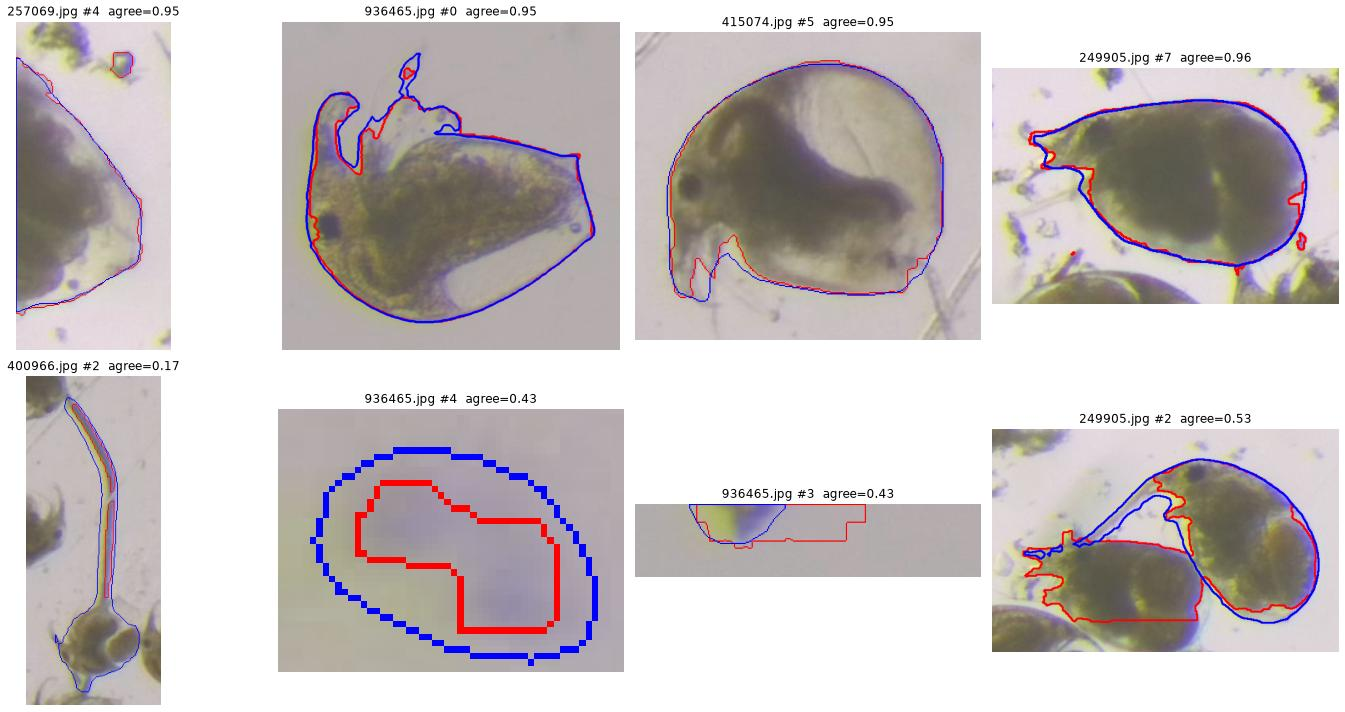

In [30]:
def zoom(name, i, ax):
    img = load(name)
    x1, y1, x2, y2 = np.array(seg_input[name]["boxes"][i]).astype(int)
    p = int(0.1 * max(x2 - x1, y2 - y1))
    ys, xs = slice(max(0, y1 - p), y2 + p), slice(max(0, x1 - p), x2 + p)
    vis = rgb(img)[ys, xs].copy()
    th = max(1, max(vis.shape[:2]) // 200)
    for m, c in [(masks["grabcut"][name][i], (255, 0, 0)), (masks["sam2"][name][i], (0, 0, 255))]:
        cnts, _ = cv2.findContours(m[ys, xs].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cnts, -1, c, th)
    ax.imshow(vis)
    ax.axis("off")


order = seg_boxes.sort_values("agree_iou")
sel = pd.concat([order.tail(4), order.head(4)])
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a in ax.ravel():
    a.axis("off")
for a, (_, r) in zip(ax.ravel(), sel.iterrows()):
    zoom(r.image, int(r.box), a)
    a.set_title(f"{r.image[-10:]} #{int(r.box)}  agree={r.agree_iou:.2f}")
plt.tight_layout()
save_fig(fig, f"{OUT}/segmentation/zoom_agree.png")
plt.show()

### GrabCut vs SAM 2

| | GrabCut | SAM 2.1 base |
|---|---|---|
| отделение от фона | тёмная середина, прозрачный край теряет, цепляет соринки | по краю панциря, фон почти не берёт |
| тонкие структуры | щетинки сливаются или пропадают | щетинки обычно есть, но на прозрачной ткани дыры |
| маска / бокс | 0.57 | 0.62 |
| маски из 2+ кусков | 6% | 0% |
| изрезанность, медиана | 1.83 | 1.53 |
| перекрытия на плотных снимках | соседние маски до IoU 0.36 | почти 0 (max 0.008) |
| время | ~0.75 с на бокс (CPU) | ~1 с на снимок, ~0.16 с на бокс (MPS) |

В среднем по всем парам у SAM 2 перекрытие даже чуть больше (0.136 против 0.124), но это из-за повторных боксов детектора на одном месте. Методы согласуются на IoU 0.82.

## 4. Анализ результатов

### 4.1 Сводная таблица

In [31]:
st_mean = stability.groupby("model")[["matched_share", "iou_mean"]].mean()
rows = []
for _, r in exp_summary.iterrows():
    rows.append({
        "experiment": f"{r.exp}: {r.model}, {r.data}",
        "params": f"conf>={CONF}, agnostic NMS {NMS_IOU}, input {r.input}, {DEVICE}",
        "images": r.images,
        "time_s": round(r.time_mean_s, 3),
        "objects": r.det_total,
        "per_image": round(r.det_per_img, 1),
        "score_mean": round(r.score_mean, 3),
        "stability": "" if r.data == "original" else
            f"matched {st_mean.loc[r.model, 'matched_share']:.2f}, IoU {st_mean.loc[r.model, 'iou_mean']:.2f}",
    })
for _, r in seg_summary.iterrows():
    rows.append({
        "experiment": f"seg: {r.method}",
        "params": f"{SEG_MODEL} boxes, score>={SEG_CONF}" + (f", margin {GC_MARGIN}, {GC_ITERS} iters, cpu" if r.method == "grabcut" else f", sam2.1_b, {DEVICE}"),
        "images": r.images,
        "time_s": round(r.time_per_img_s, 3),
        "objects": r.boxes,
        "per_image": round(r.boxes / r.images, 1),
        "score_mean": np.nan,
        "stability": f"area/box {r.area_ratio_mean:.2f}, multi-part {r.multi_component_share:.2f}, inst overlap {r.inst_overlap_mean:.3f}",
    })
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT}/summary.csv", index=False)

with open(f"{OUT}/summary.json", "w") as f:
    json.dump({
        "detection": {"conf": CONF, "nms_iou": NMS_IOU, "max_area": MAX_AREA, "device": DEVICE,
                      "yolo": YOLO_W, "yolo_imgsz": YOLO_SIZE, "frcnn": "fasterrcnn_resnet50_fpn_v2 COCO_V1",
                      "augs": list(DET_AUGS), "experiments": exp_summary.to_dict("records"),
                      "stability": stability.to_dict("records")},
        "segmentation": {"boxes_from": SEG_MODEL, "conf": SEG_CONF, "images": SEG_IMAGES,
                         "grabcut": {"margin": GC_MARGIN, "iters": GC_ITERS}, "sam": "sam2.1_b.pt",
                         "summary": seg_summary.to_dict("records")},
    }, f, indent=1, default=float)
summary

,experiment,params,images,time_s,objects,per_image,score_mean,stability
0,"1: yolo11, original","conf>=0.05, agnostic NMS 0.5, input 1024 (long side), mps",66,0.116,753,11.4,0.168,
1,"2: yolo11, augmented","conf>=0.05, agnostic NMS 0.5, input 1024 (long side), mps",528,0.112,5492,10.4,0.176,"matched 0.72, IoU 0.94"
2,"3: faster_rcnn, original","conf>=0.05, agnostic NMS 0.5, input 800 (short side), mps",66,0.468,538,8.2,0.316,
3,"4: faster_rcnn, augmented","conf>=0.05, agnostic NMS 0.5, input 800 (short side), mps",528,0.473,3979,7.5,0.308,"matched 0.68, IoU 0.90"
4,seg: grabcut,"faster_rcnn boxes, score>=0.2, margin 0.15, 5 iters, cpu",9,4.529,54,6.0,NaN,"area/box 0.57, multi-part 0.06, inst overlap 0.124"
5,seg: sam2,"faster_rcnn boxes, score>=0.2, sam2.1_b, mps",9,0.953,54,6.0,NaN,"area/box 0.62, multi-part 0.00, inst overlap 0.136"


| эксперимент | что видно |
|---|---|
| 1. YOLO11, исходные | быстро, много боксов на мусоре, медиана score ~0.1, мелких рачков пропускает |
| 2. YOLO11, аугментации | к яркости/контрасту/размытию устойчиво (81-86%), на шуме и гамме теряет 45-63% боксов |
| 3. Faster R-CNN, исходные | в 4 раза медленнее, больше рачков, меньше мусора, есть вложенные боксы |
| 4. Faster R-CNN, аугментации | 65-66% на яркости/контрасте/размытии, на шуме половина боксов теряется и 300 новых |
| GrabCut | нормально на одиночных рачках, на плотных цепляет соседей, теряет прозрачный край |
| SAM 2 | чистые маски и разделение соседей, но целиком зависит от бокса |

### 4.2 Анализ ошибок

Эталона нет, ориентир - пятна из 1.1 (на картинках зелёные). Они сами склеивают рачков и ловят мусор, так что цифры примерные.

In [32]:
def covered(a, b, thr):
    if len(a) == 0:
        return np.zeros(0, bool)
    if len(b) == 0:
        return np.zeros(len(a), bool)
    iou = torchvision.ops.box_iou(torch.tensor(a, dtype=torch.float32), torch.tensor(b, dtype=torch.float32))
    return iou.numpy().max(1) >= thr


blob_boxes = {name: np.array([x["box"] for x in blobs(load(name))]).reshape(-1, 4) for name in files}
err_rows = []
for model in MODELS:
    for name in files:
        d = dets[(dets.model == model) & (dets.aug == "original") & (dets.image == name)]
        b = d[["x1", "y1", "x2", "y2"]].to_numpy()
        bb = blob_boxes[name]
        err_rows.append({"model": model, "image": name, "blobs": len(bb), "det": len(b), "group": d.group.sum(),
                         "blobs_missed": (~covered(bb, b[~d.group.to_numpy()], 0.3)).sum(),
                         "det_no_blob": (~covered(b, bb, 0.1)).sum()})
errs = pd.DataFrame(err_rows)
errs.to_csv(f"{OUT}/detection/errors_vs_blobs.csv", index=False)
e = errs.groupby("model")[["blobs", "det", "group", "blobs_missed", "det_no_blob"]].sum()
e["missed_share"] = e.blobs_missed / e.blobs
e["no_blob_share"] = e.det_no_blob / e.det
e.round(3)

,blobs,det,group,blobs_missed,det_no_blob,missed_share,no_blob_share
model,,,,,,,
faster_rcnn,455,538,37,203,225,0.446,0.418
yolo11,455,753,21,211,477,0.464,0.633


~45% пятен без бокса у обеих моделей (завышено из-за склеек и мусора). Боксов без пятна у YOLO 63%, у Faster R-CNN 42%.

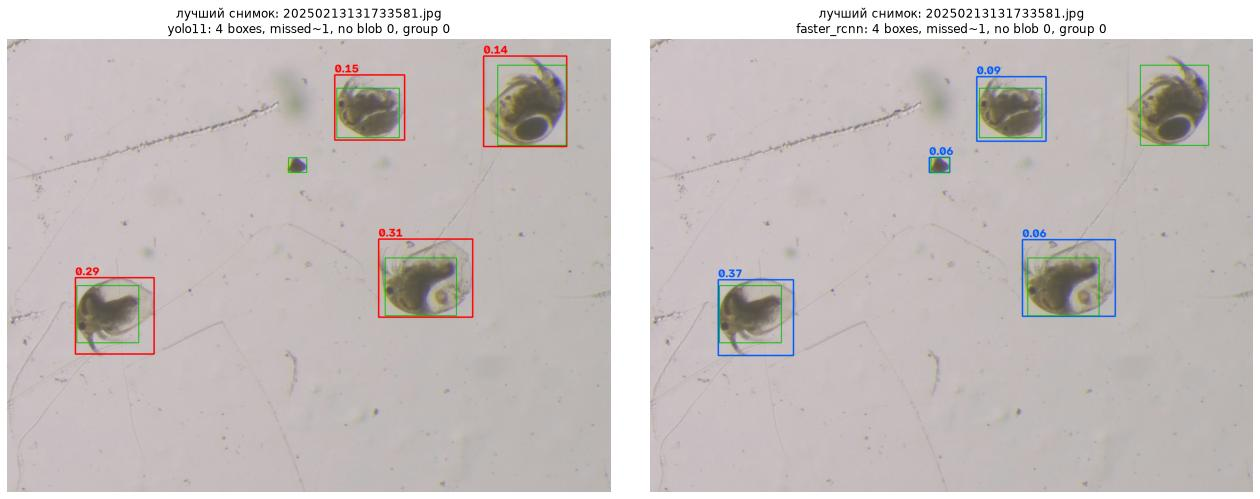

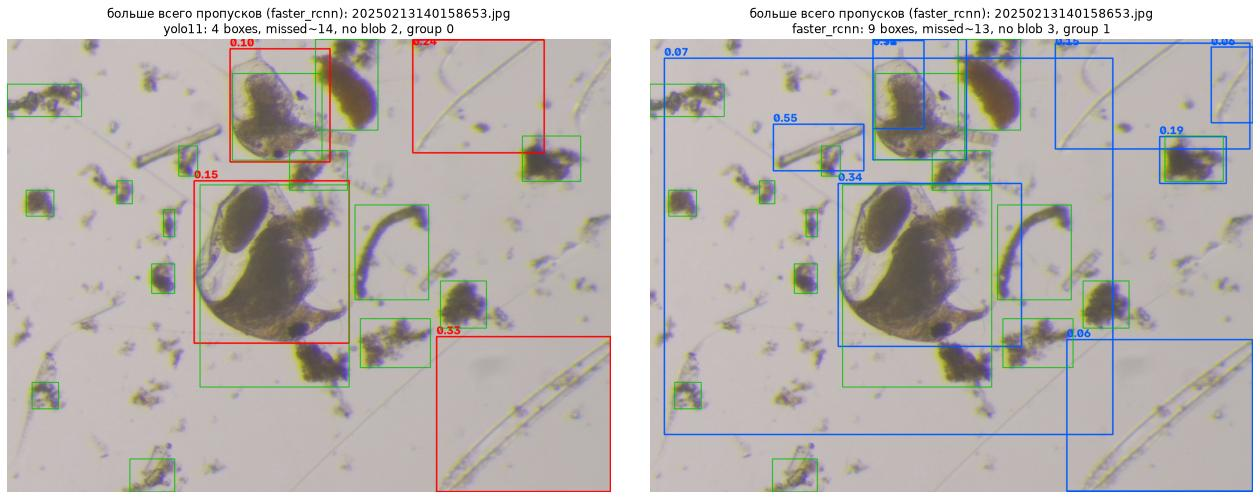

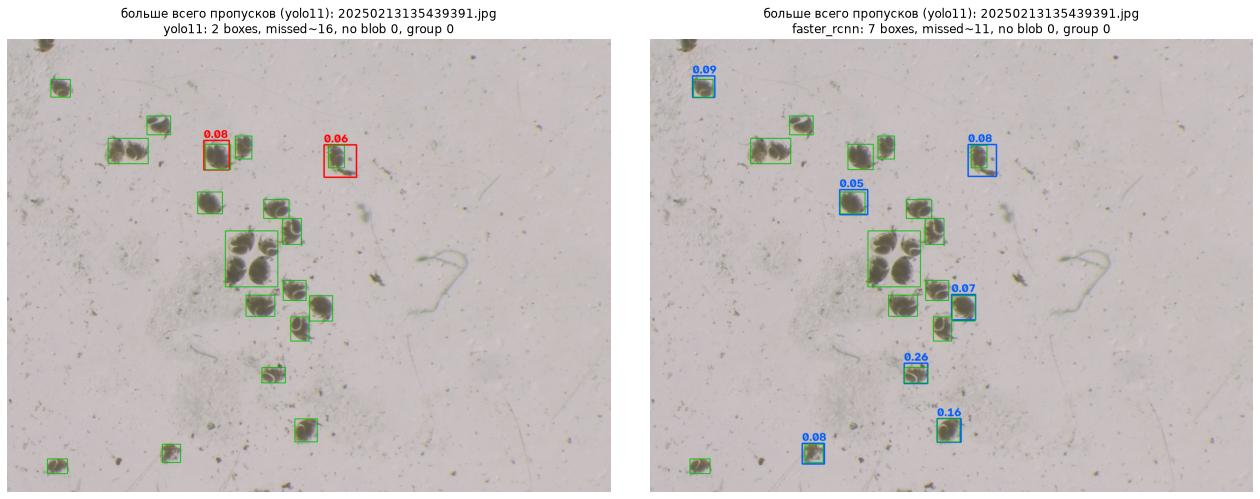

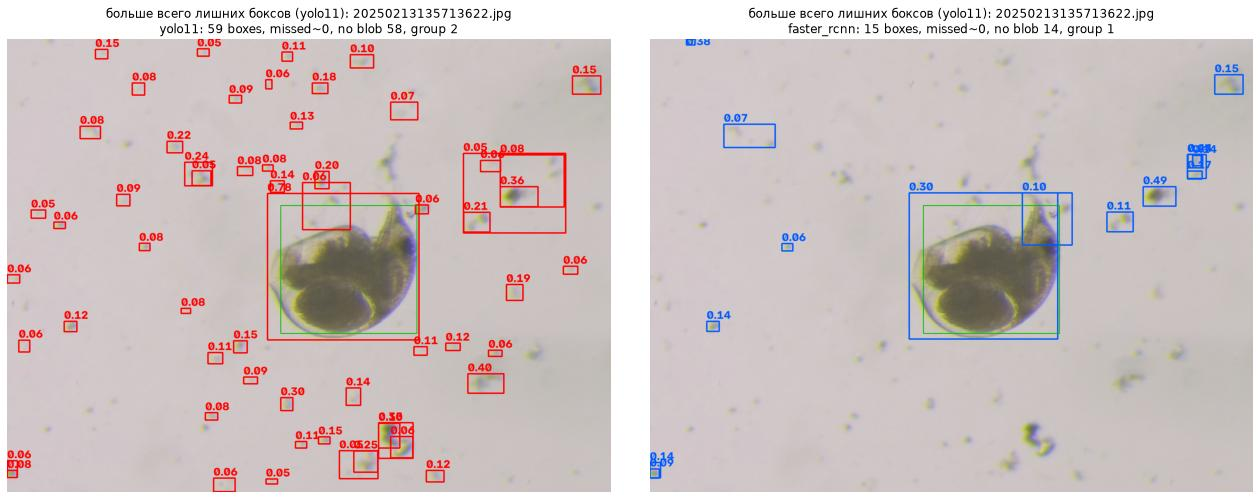

In [33]:
total = errs.assign(bad=errs.blobs_missed + errs.det_no_blob + errs.group).groupby("image").bad.sum()
cases = {
    "лучший снимок": total[total.index.isin(main.image)].sort_values().index[0],
    "больше всего пропусков (faster_rcnn)": errs[errs.model == "faster_rcnn"].sort_values("blobs_missed").image.iloc[-1],
    "больше всего пропусков (yolo11)": errs[errs.model == "yolo11"].sort_values("blobs_missed").image.iloc[-1],
    "больше всего лишних боксов (yolo11)": errs[errs.model == "yolo11"].sort_values("det_no_blob").image.iloc[-1],
}
for title, name in cases.items():
    img = load(name)
    fig, ax = plt.subplots(1, 2, figsize=(18, 6.8))
    for a, (model, color) in zip(ax, [("yolo11", (255, 0, 0)), ("faster_rcnn", (0, 90, 255))]):
        b, s = boxes_of(model, "original", name, col="")
        vis = draw(img, b, s, color)
        for x1, y1, x2, y2 in blob_boxes[name].astype(int):
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 190, 0), 2)
        r = errs[(errs.model == model) & (errs.image == name)].iloc[0]
        a.imshow(vis)
        a.set_title(f"{title}: {name}\n{model}: {len(b)} boxes, missed~{r.blobs_missed}, no blob {r.det_no_blob}, group {r.group}")
        a.axis("off")
    plt.tight_layout()
    save_fig(fig, f"{OUT}/detection/case_{name.rsplit('.', 1)[0]}.jpg")
    plt.show()

- `...131733581` удачный: 4 отдельных рачка, YOLO нашла все
- `...135713622` один рачок и мусор, у YOLO 59 боксов
- `...135439391` ~18 мелких рачков, YOLO нашла 2, Faster R-CNN 7
- `...140158653` боксы на волокнах и бокс почти на весь кадр

Худшие маски: низкая оценка SAM 2 и большая разница площадей.

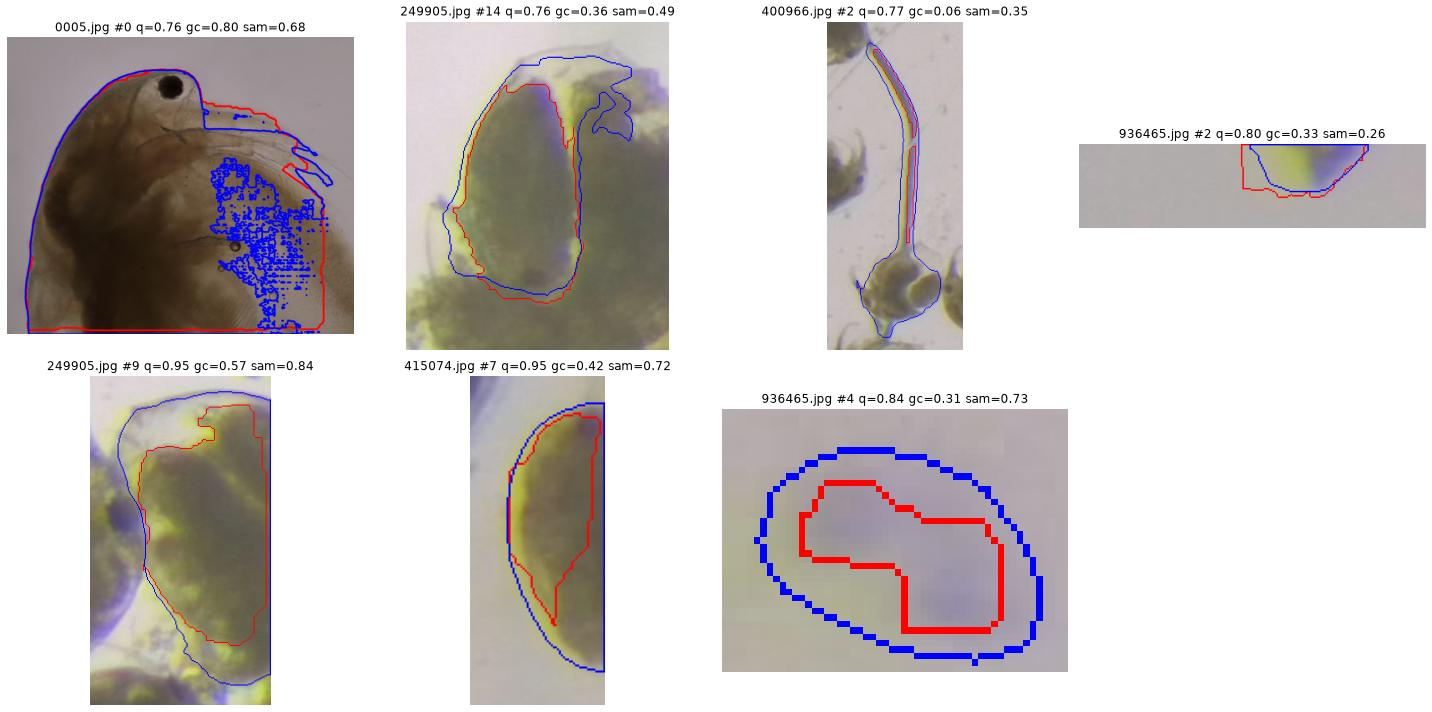

In [34]:
bad = pd.concat([seg_boxes.sort_values("sam_quality").head(4),
                 seg_boxes.assign(d=(seg_boxes.grabcut_area_ratio - seg_boxes.sam2_area_ratio).abs()).sort_values("d").tail(4)])
bad = bad.drop_duplicates(["image", "box"]).head(8)
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a in ax.ravel():
    a.axis("off")
for a, (_, r) in zip(ax.ravel(), bad.iterrows()):
    zoom(r.image, int(r.box), a)
    a.set_title(f"{r.image[-10:]} #{int(r.box)} q={r.sam_quality:.2f} gc={r.grabcut_area_ratio:.2f} sam={r.sam2_area_ratio:.2f}")
plt.tight_layout()
save_fig(fig, f"{OUT}/segmentation/zoom_bad.png")
plt.show()

Причины ошибок:
- шум: у YOLO пропадает 63% боксов, у Faster R-CNN появляются сотни ложных
- низкий контраст: мелкие полупрозрачные рачки пропускаются, GrabCut теряет прозрачный край
- перекрытия: групповые и вложенные боксы, GrabCut затягивает соседа в маску
- неточные боксы (волокно, соринка, пара рачков, край кадра) - главная причина плохих масок, SAM 2 уверенно сегментирует то, что в боксе

### 4.3 Выводы

COCO-детекторы без дообучения годятся только как грубый поиск кандидатов: классы случайные, уверенность низкая, мелких рачков пропускают, на мусор срабатывают. Из двух лучше Faster R-CNN, YOLO быстрее, но шумит на мусоре. Предсказания меняются даже от отражения, сильнее всего от шума.

SAM 2 по боксам без обучения даёт маски заметно лучше GrabCut, но всё упирается в качество боксов. Чтобы было нормально, детектор надо дообучить хотя бы на нескольких десятках боксов, а SAM 2 оставить для масок.